# Who gets the good Batman stories?

Which writers, artists, and characters turn up in BatChat's favorites? Which series do best? And what changes when we compare books from the same decade?

[BatChat](https://comicsxf.com/batchat-rankings/) hosts **Matt Lazorwitz and Will Nevin** have ranked **740 Batman stories**. **Rank 1 is best, so lower is better throughout.** We start with the leaderboards, then look at eras, creative teams, and plots.

By [Dan Ofer](https://scholar.google.com/citations?user=uDx2ItYAAAAJ) · [Dataset](https://www.kaggle.com/datasets/danofer/batchat-batman-rankings) · [Code and sources](https://github.com/ddofer/BatRank)

In [1]:
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import HTML, display

# Kaggle mounts the dataset under /kaggle/input; locally, `make share` stages it in data/kaggle.
DATA = next(
    p.parent
    for root in ["/kaggle/input", "data/kaggle", "../data/kaggle"]
    for p in Path(root).rglob("stories.csv")
)
COLORS = {"blue": "#2767A0", "orange": "#D57927", "green": "#26806B", "grey": "#75818C"}
ROLES = ["writers", "pencilers", "inkers", "colorists", "letterers", "editors"]
sns.set_theme(
    style="ticks",
    font_scale=1.05,
    rc={"axes.spines.top": False, "axes.spines.right": False, "axes.titleweight": "bold"},
)
pd.set_option("display.max_colwidth", 70)


def split_set(value):
    """Split a |-separated field into a list; missing values give an empty list."""
    return [item for item in value.split("|") if item] if isinstance(value, str) else []


def collapsible(summary, table, note="", **to_html):
    """Show a long table inside a click-to-expand block."""
    body = table.to_html(escape=True, **to_html)
    return HTML(f"<details><summary>{summary}</summary><p>{note}</p>{body}</details>")


stories = pd.read_csv(DATA / "stories.csv")
issues = pd.read_csv(DATA / "issues.csv")
creators = pd.read_csv(DATA / "creators.csv")
credits = pd.read_csv(DATA / "story_creators.csv")
N = len(stories)

# Credits for the selected story only, not unrelated backups in the same issue.
story_credits = credits[credits.credit_scope.eq("selected_narrative")]
# Stories whose every issue has a resolved story and full creator credits.
fully_credited = stories.loc[
    stories.metadata_complete
    & stories.substory_attribution_coverage.eq(1)
    & stories.narrative_credit_issue_coverage.eq(1),
    "story_id",
]
print(f"{N:,} ranked stories · {len(issues):,} issues · snapshot {stories.snapshot_date.iloc[0]}")

740 ranked stories · 2,434 issues · snapshot 2026-10-21


## The top and bottom of the list

Each row of `stories.csv` is one ranked story. Here are both ends of the list.

In [2]:
columns = {
    "rank": "Rank",
    "title": "Story",
    "narrative_writers": "Writers",
    "narrative_pencilers": "Pencilers",
    "cover_year_start": "Year",
}
ends = pd.concat([stories.head(10), stories.tail(5)])[list(columns)].rename(columns=columns)
ends["Year"] = ends.Year.astype("Int64")
ends[["Writers", "Pencilers"]] = ends[["Writers", "Pencilers"]].apply(
    lambda col: col.str.replace("|", ", ", regex=False)
)
ends.set_index("Rank")

,Story,Writers,Pencilers,Year
Rank,,,,
1,Year One,Frank Miller,Dave Mazzucchelli,1987
2,Ego,Darwyn Cooke,Darwyn Cooke,2000
3,Cold Days,Tom King,Lee Weeks,2018
4,The Long Halloween,Jeph Loeb,Tim Sale,1996
5,The Joker,"James Tynion IV, Matthew Rosenberg","Francesco Francavilla, Giuseppe Camuncoli, Guillem March, Stefano ...",2020
6,Batman/Dracula: Red Rain OGN,Doug Moench,Kelley Jones,1992
7,Some Of These Days,Tom King,"Lee Weeks, Michael Lark",2018
8,The Dark Knight Returns,Frank Miller,Frank Miller,1986
9,The Court of Owls,Scott Snyder,Greg Capullo,2011


## Who wrote them, and when?

**Chuck Dixon leads with 34 stories**, followed by Alan Grant with 31 and Dennis O'Neil with 28. These counts describe the podcast's list, not the writers' full output.

The decade chart has a surprise: the **2020s' median rank of 300** sits close to the **1980s' 310**. Every era has favorites and disappointments. Dots show medians; bars span the middle half of the ranks. **Farther left is better.**

<details><summary>What's included?</summary>

Writer counts use the 677 stories with complete writer credits. Co-written stories count for each writer. The decade chart uses the 733 stories with a known cover year; arcs use their first issue. The 1930s have only three stories. These are books the hosts chose, not random samples of each decade.

</details>

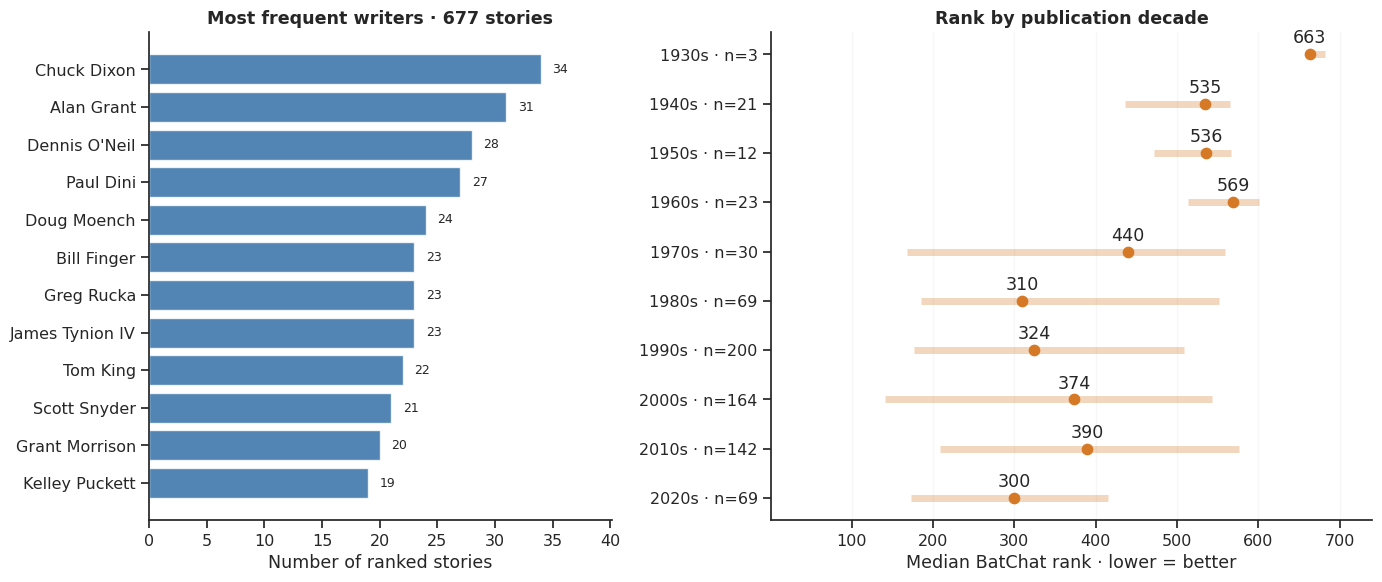

In [3]:
writer_links = story_credits[
    story_credits.role.eq("writers") & story_credits.story_id.isin(fully_credited)
]
writer_profiles = (
    writer_links.merge(stories[["story_id", "rank"]], on="story_id", validate="many_to_one")
    .groupby("creator_id")
    .agg(readings=("story_id", "nunique"), median_rank=("rank", "median"))
    .merge(creators[["creator_id", "name"]], on="creator_id", validate="one_to_one")
    .sort_values(["readings", "name"], ascending=[False, True])
)
frequent = writer_profiles.head(12).iloc[::-1]

era = stories.dropna(subset=["cover_year_start"]).copy()
era["decade"] = (era.cover_year_start // 10 * 10).astype(int)
era_profile = era.groupby("decade")["rank"].agg(
    n="size", median_rank="median", q25=lambda v: v.quantile(0.25), q75=lambda v: v.quantile(0.75)
)

fig, axes = plt.subplots(1, 2, figsize=(14, 6), gridspec_kw={"width_ratios": [1, 1.3]})
ax = axes[0]
ax.barh(frequent.name, frequent.readings, color=COLORS["blue"], alpha=0.8)
for pos, count in enumerate(frequent.readings):
    ax.text(count + 1, pos, str(count), va="center", fontsize=9)
ax.set(
    xlim=(0, frequent.readings.max() * 1.18),
    xlabel="Number of ranked stories",
    title=f"Most frequent writers · {writer_links.story_id.nunique()} stories",
)
ax = axes[1]
positions = np.arange(len(era_profile))
ax.hlines(positions, era_profile.q25, era_profile.q75, lw=5, alpha=0.3, color=COLORS["orange"])
ax.scatter(era_profile.median_rank, positions, color=COLORS["orange"], s=55)
for pos, value in enumerate(era_profile.median_rank):
    ax.annotate(
        f"{value:.0f}", (value, pos), xytext=(0, 8), textcoords="offset points", ha="center"
    )
ax.set(
    yticks=positions,
    yticklabels=[f"{d}s · n={int(row.n)}" for d, row in era_profile.iterrows()],
    xlim=(1, N),
    xlabel="Median BatChat rank · lower = better",
    title="Rank by publication decade",
)
ax.invert_yaxis()
ax.xaxis.grid(True, alpha=0.15)
fig.tight_layout()
plt.show()

## The highest- and lowest-ranked creators

Who has a run of favorites? Who keeps turning up near the bottom? We compare writers and pencilers separately; each needs **at least five fully credited stories**.

Boxes show the middle half of each creator's stories, with the median inside; faint dots are individual stories. **Left is better.** A shared story counts for every contributor. These results describe the books BatChat chose, not whole careers.

Bruce Timm leads the writers, with a median rank of **39 across five stories**. Michael Lark leads the pencilers at **40.5 across six**. Several low medians belong to creators who contributed to highly ranked anthologies. At the other end, J.M. DeMatteis has a median of **622 across nine stories**. Five stories is a small sample, so check the spread in the tables.

Raise the minimum to **ten stories** and the leaders become **Ed Brubaker** for writing and **Tim Sale** for pencils.

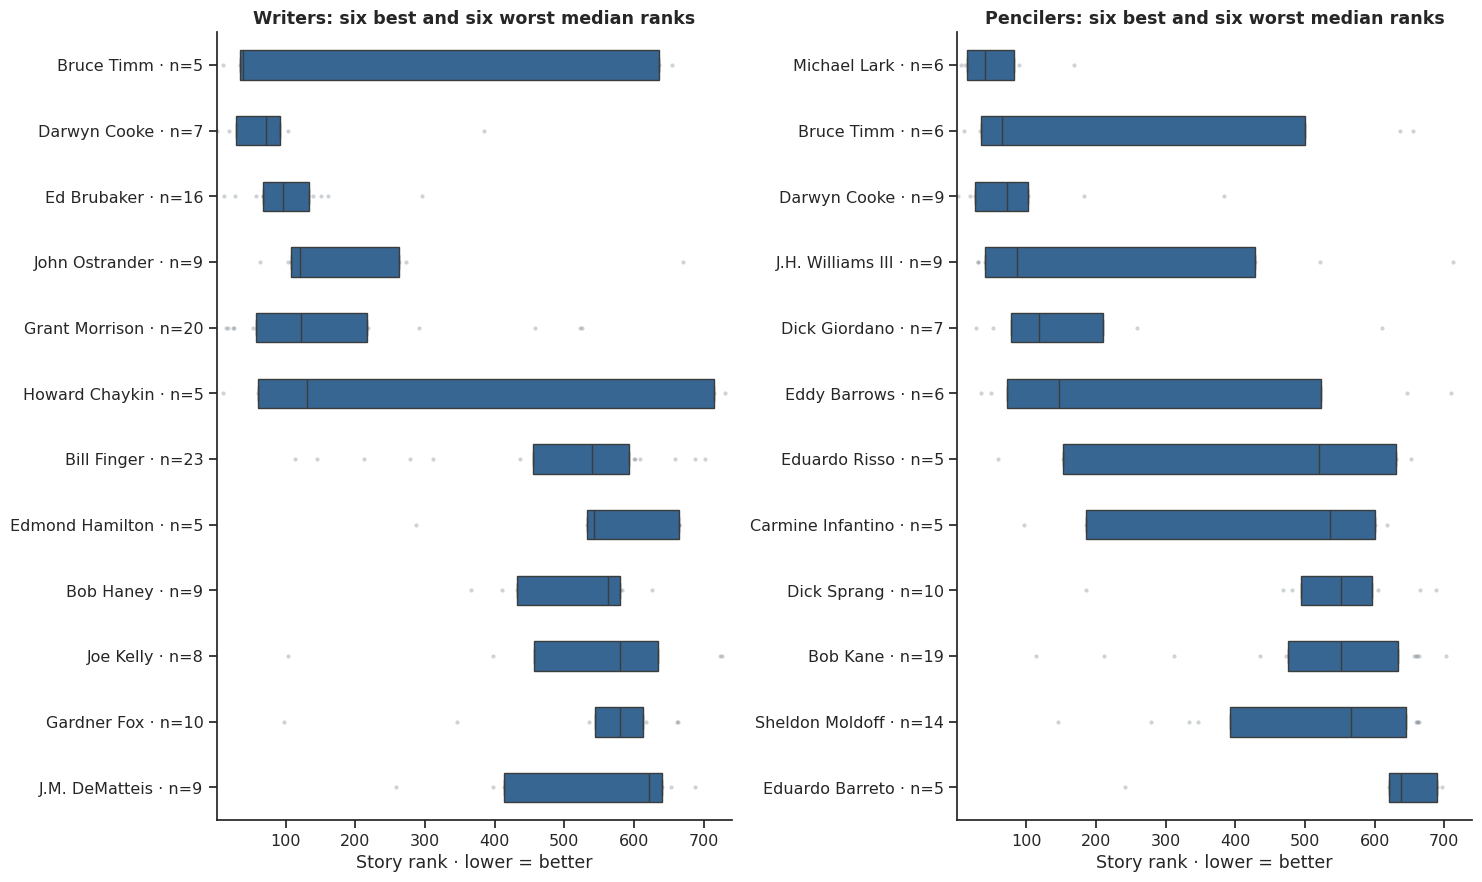

Name,Stories,Median rank,Best rank,Best story,Worst rank,Worst story
Bruce Timm,5,39.0,10,Batman: Black and White Vol.1,655,Batman: Harley & Ivy #1-3
Darwyn Cooke,7,72.0,2,Ego,384,Justice League: The New Frontier Special
Ed Brubaker,16,96.5,12,Soft Targets,296,Fearless
John Ostrander,9,121.0,63,A Savage Innocence,670,Grotesk
Grant Morrison,20,121.5,15,Batman: R.I.P.,526,The Three Ghosts of Batman
Howard Chaykin,5,130.0,10,Batman: Black and White Vol.1,730,Batman: Dark Allegiances
Matt Wagner,6,155.5,10,Batman: Black and White Vol.1,469,Faces
Jeph Loeb,13,173.0,4,The Long Halloween,615,Lord of the Ring
Greg Rucka,23,194.0,12,Soft Targets,615,Lord of the Ring
Jeff Parker,9,211.0,126,Batman ’66 V.1,326,Batman/Santa Claus: Silent Knight #1-4


Name,Stories,Median rank,Best rank,Best story,Worst rank,Worst story
Michael Lark,6,40.5,7,Some Of These Days,168,Batman: Nine Lives OGN
Bruce Timm,6,65.5,10,Batman: Black and White Vol.1,655,Batman: Harley & Ivy #1-3
Darwyn Cooke,9,72.0,2,Ego,384,Justice League: The New Frontier Special
J.H. Williams III,9,87.0,30,Six Fingers,713,Chasing Clay
Dick Giordano,7,118.0,28,To Kill a Legend,610,Batman: Hollywood Knights #1-3
Eddy Barrows,6,147.5,35,Cheer,710,Grounded
John Romita Jr.,5,153.0,33,The Dark Knight Returns: The Last Crusade,728,Superman: Year One #3
Matt Wagner,6,155.5,10,Batman: Black and White Vol.1,469,Faces
Lee Garbett,5,161.0,26,Final Crisis,219,Batgirl Rising- Point of New Origin
Álvaro Martínez Bueno,6,169.5,49,Rise of the Batmen,480,Batman & Robin Eternal #1-26


Name,Stories,Median rank,Best rank,Best story,Worst rank,Worst story
Michael Lark,6,40.5,7,Some Of These Days,168,Batman: Nine Lives OGN
Darwyn Cooke,7,72.0,2,Ego,384,Justice League: The New Frontier Special
J.H. Williams III,6,75.5,31,Beautiful People,522,The Club of Heroes
Bruce Timm,7,92.0,10,Batman: Black and White Vol.1,655,Batman: Harley & Ivy #1-3
Klaus Janson,6,120.0,8,The Dark Knight Returns,193,DC Pride 2021
Norm Breyfogle,9,120.0,22,Knightfall Part 1: The Broken Bat,481,Ecstasy
Drew Geraci,5,122.0,26,Final Crisis,314,I was the Love Slave of a Planet Based Killer
Eber Ferreira,5,140.0,35,Cheer,646,Perpetual Motion
Raúl Fernández,6,169.5,49,Rise of the Batmen,480,Batman & Robin Eternal #1-26
Tim Sale,11,173.0,4,The Long Halloween,703,The Wedding


Name,Stories,Median rank,Best rank,Best story,Worst rank,Worst story
Tatjana Wood,5,119.0,20,The Garden of Earthly Delights,222,Riddles
Nathan Fairbairn,6,129.0,25,Leviathan Strikes,355,Superheavy
Adriano Lucas,7,140.0,35,Cheer,369,New Year’s Evil V.2 #1
Matt Hollingsworth,13,168.0,24,Half a Life,737,Batman: Curse of the White Knight #1-8
Tony Aviña,11,170.0,26,Final Crisis,675,Golden Dawn
Marissa Louise,5,193.0,65,Sword of Azrael (2022) #1-6,557,"Harley Quinn: The Animated Series- The Eat, Bang, Kill Tour #1-6"
James Sinclair,6,201.0,44,Blink,549,Terror
Dave Stewart,28,237.0,19,The New Frontier,630,A Grim Knight in Gotham
José Villarrubia,6,245.0,53,Batman: The Return of Bruce Wayne #1-6,703,The Wedding
Romulo Fajardo Jr.,5,250.0,184,Batman: Eternal V.3,590,The Princess and the Knight


Name,Stories,Median rank,Best rank,Best story,Worst rank,Worst story
Kurt Hathaway,5,107.0,44,Blink,549,Terror
Sean Konot,7,132.0,27,Anodyne,704,The Fishy Laugh
Ariana Maher,5,193.0,86,DC Pride 2022,392,Gotham Villains 80th Anniversary Giant
Clem Robins,17,194.0,12,Soft Targets,731,The Surrogate
Tom Napolitano,16,223.0,87,Batman: Black and White V.4,717,Fear of the Dark
Richard Starkings,28,231.0,4,The Long Halloween,718,"Batman: The Blue, The Grey, and the Bat"
John Workman,17,235.0,10,Batman: Black and White Vol.1,728,Superman: Year One #3
Todd Klein,70,251.0,1,Year One,734,Batman: White Knight #1-8
Troy Peteri,13,254.0,40,Father’s Day,709,Tales from the Dark Multiverse: Batman- Hush
Willie Schubert,36,287.5,24,Half a Life,697,Knightquest: The Search


Name,Stories,Median rank,Best rank,Best story,Worst rank,Worst story
Mark Chiarello,12,66.0,2,Ego,585,Batman: Noel OGN
E. Nelson Bridwell,7,147.0,14,Strange Apparitions,711,The Last Batman Story–?
Matt Idelson,20,172.0,12,Soft Targets,710,Grounded
Nachie Castro,19,194.0,12,Soft Targets,714,Brothers in Blood
Aniz Ansari,9,223.0,38,Batman ’66: The Lost Episode,409,Injustice: Gods Among Us Vol.2
Michael McCalister,5,224.0,86,DC Pride 2022,271,Hammer of Justice
Chuck Kim,12,231.5,4,The Long Halloween,540,Werewolf
Rob Levin,6,249.5,69,Everyday.,676,Manslaughter
Dan Raspler,27,255.0,29,Batman: The Cult #1-4,629,Robin Lives!
Jim Chadwick,24,262.0,38,Batman ’66: The Lost Episode,674,Injustice: Gods Among Us Year 4 Vol. 2


In [4]:
creator_stories = (
    story_credits[story_credits.story_id.isin(fully_credited)]
    .merge(creators[["creator_id", "name"]], on="creator_id", validate="many_to_one")
    .merge(stories[["story_id", "title", "rank"]], on="story_id", validate="many_to_one")
)
creator_rankings = (
    creator_stories.sort_values("rank")
    .groupby(["role", "creator_id", "name"])
    .agg(
        stories=("story_id", "nunique"),
        median_rank=("rank", "median"),
        best_rank=("rank", "first"),
        best_story=("title", "first"),
        worst_rank=("rank", "last"),
        worst_story=("title", "last"),
    )
    .reset_index()
)


def rank_boxes(ax, entries, key, labels, color):
    """Box of the middle half plus one faint dot per story, in the order of `labels`."""
    chart = entries[entries[key].isin(labels.index)].assign(label=lambda d: d[key].map(labels))
    common = dict(data=chart, x="rank", y="label", order=labels.tolist(), ax=ax)
    sns.stripplot(**common, color=COLORS["grey"], alpha=0.35, size=3, jitter=False, zorder=0)
    sns.boxplot(**common, color=color, whis=0, showfliers=False, width=0.45)
    ax.set(xlabel="Story rank · lower = better", ylabel="", xlim=(1, N))


fig, axes = plt.subplots(1, 2, figsize=(15, 9), sharex=True)
for ax, role in zip(axes, ["writers", "pencilers"]):
    eligible = creator_rankings.query("role == @role and stories >= 5").sort_values("median_rank")
    extremes = pd.concat([eligible.head(6), eligible.tail(6)]).set_index("creator_id")
    labels = extremes.name + " · n=" + extremes.stories.astype(str)
    rank_boxes(
        ax, creator_stories[creator_stories.role.eq(role)], "creator_id", labels, COLORS["blue"]
    )
    ax.set_title(f"{role.capitalize()}: six best and six worst median ranks")
fig.tight_layout()
plt.show()

shown_columns = [
    "name",
    "stories",
    "median_rank",
    "best_rank",
    "best_story",
    "worst_rank",
    "worst_story",
]
for role in ROLES:
    table = creator_rankings.query("role == @role and stories >= 5").sort_values("median_rank")
    display(
        collapsible(
            f"{role.capitalize()}: all {len(table)} names with five or more stories",
            table[shown_columns].rename(columns=lambda c: c.replace("_", " ").capitalize()),
            "Median rank: lower is better. Best and worst examples show the range.",
            index=False,
        )
    )

## Which heroes and villains get the better stories?

Barbara Gordon's **52 featured appearances** have a median rank of **235.5**. Bruce Wayne's **479** have **379**. Many books feature both.

Below are the **15 most frequent names in each role**. Dots show median ranks; bars span the middle half. **Left is better.** The dotted line marks the median across all 682 eligible stories.

"Featured" usually means a hero, but villains can star too. "Antagonist" describes a character's role in that story. Neither label measures page time.

<details><summary>How names and roles are counted</summary>

We require complete character records for the selected stories. Cameos, mentions, flashbacks, and depictions are excluded. Each name counts once per story and role.

Matching names are combined across universe labels. Riddler's Nashton, Nygma, and Nigma spellings are combined, as are Mr. Freeze's Schivel/Fries and Terry McGinnis's spelling variants. Groups and unnamed characters are kept.

The expandable tables below list every recorded name, with counts and best- and worst-ranked examples.

</details>

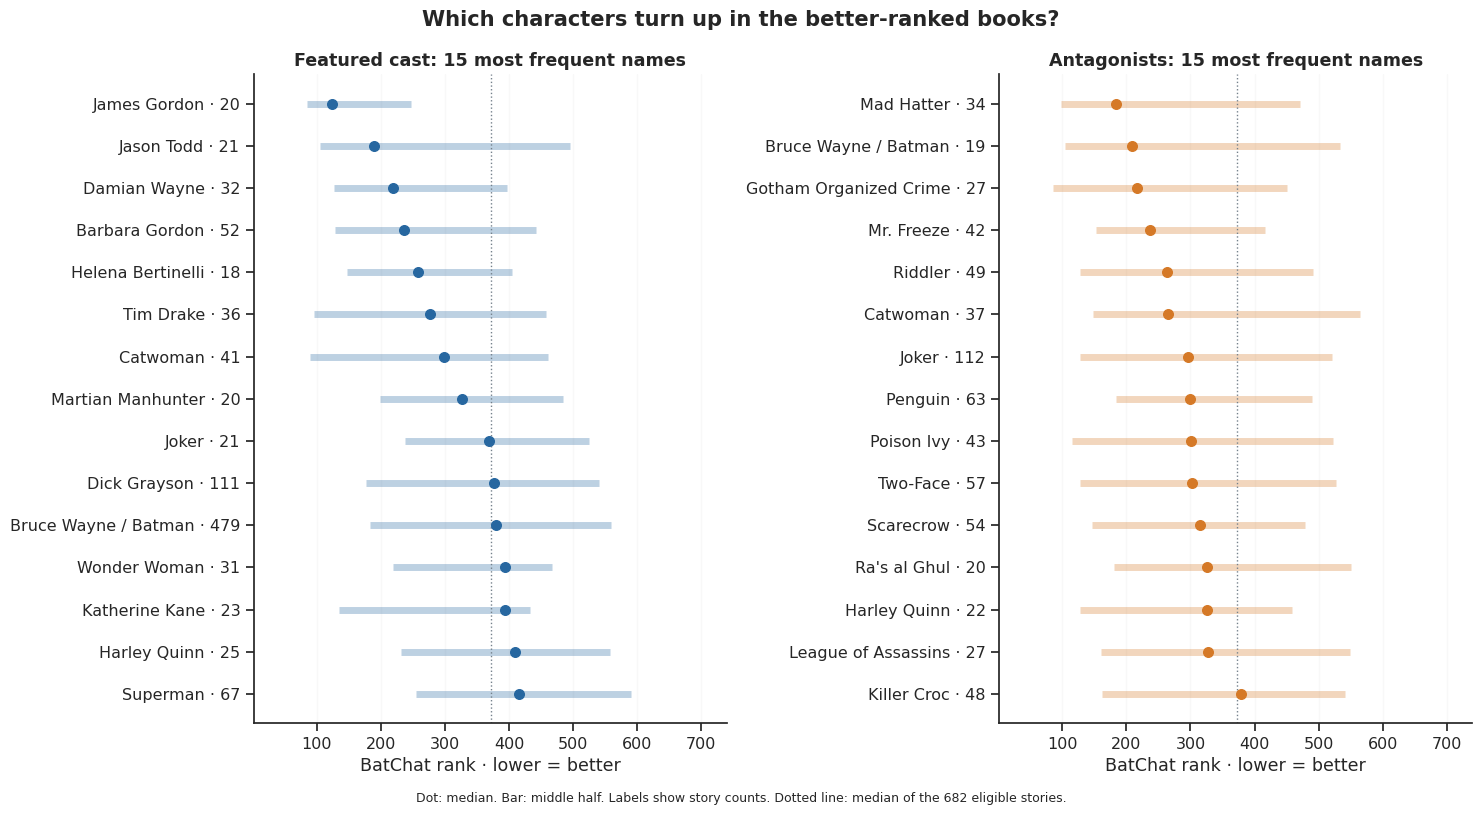

Character,Stories,Median rank,Best rank,Worst rank
Norman McCay,1,13.0,13,13
Josephine MacDonald,2,18.0,12,24
Challengers of the Unknown,1,19.0,19,19
Clay,1,19.0,19,19
Flying Cloud,1,19.0,19,19
Gunner MacKay,1,19.0,19,19
John Wilson,1,19.0,19,19
Kyle Morgan,1,19.0,19,19
Lester Davis,1,19.0,19,19
Losers,1,19.0,19,19


Character,Stories,Median rank,Best rank,Worst rank
Branden,1,1.0,1,1
Gillian B. Loeb,1,1.0,1,1
Johnny Viti,1,1.0,1,1
Carla Falcone,1,4.0,4,4
Donald Sullivan,1,4.0,4,4
Frankie Carbone,1,4.0,4,4
Jimmy Murphy,1,4.0,4,4
Joe Bandano,1,4.0,4,4
Kevin Kelly,1,4.0,4,4
Luca Mareli,1,4.0,4,4


1,103 antagonist entries appear only once.


In [5]:
cast_known = stories[
    stories.cast_scope.eq("selected_narratives") & stories.cast_issue_coverage.eq(1)
].copy()
cast_known["decade"] = (cast_known.cover_year_start // 10 * 10).astype("Int64")

# These spellings identify the same character; each character counts once per story.
character_aliases = {
    "Edward Nashton": "Riddler",
    "Edward Nigma": "Riddler",
    "Edward Nygma": "Riddler",
    "Doctor Schivel": "Mr. Freeze",
    "Victor Fries": "Mr. Freeze",
    "Terrence McGinnis": "Terry McGinnis",
}
# Display names for civilian identities that readers know by another name.
display_names = {
    "Jervis Tetch": "Mad Hatter",
    "Selina Kyle": "Catwoman",
    "Victor Fries": "Mr. Freeze",
    "Oswald Cobblepot": "Penguin",
    "Pamela Isley": "Poison Ivy",
    "Harvey Dent": "Two-Face",
    "Jonathan Crane": "Scarecrow",
    "Harleen Quinzel": "Harley Quinn",
    "Waylon Jones": "Killer Croc",
    "Bruce Wayne": "Bruce Wayne / Batman",
    "Richard Grayson": "Dick Grayson",
    "Kal-El": "Superman",
    "Timothy Drake": "Tim Drake",
    "Diana of Themyscira": "Wonder Woman",
    "J'onn J'onzz": "Martian Manhunter",
    "Victor Sage": "The Question (Vic Sage)",
    "Michael Carter": "Booster Gold",
    "Theodore Kord": "Blue Beetle (Ted Kord)",
    "Roger Hayden": "Psycho-Pirate",
    "Dumpson Tweed": "Tweedledum",
    "Deever Tweed": "Tweedledee",
    "Raymond Palmer": "The Atom (Ray Palmer)",
    "Rex Mason": "Metamorpho",
    "Scott Free": "Mister Miracle",
    "Ted Grant": "Wildcat",
    "Thomas Blake": "Catman",
    "Aaron Helzinger": "Amygdala",
    "Simon Hurt": "Doctor Hurt",
    "Maximillian Zeus": "Maxie Zeus",
}


def entity_associations(frame, column):
    """One row per story and character, with universe suffixes such as '(New Earth)' removed."""
    out = frame[["story_id", "rank", "cover_year_start", column]].copy()
    out["entity"] = out[column].map(split_set)
    out = out.explode("entity").dropna(subset=["entity"])
    out["entity"] = out.entity.str.replace(r" \([^()]+\)$", "", regex=True)
    out["entity"] = out.entity.replace(character_aliases)
    return out.drop_duplicates(["story_id", "entity"])


entries = {
    "Featured cast": entity_associations(cast_known, "featured_entity_ids"),
    "Antagonists": entity_associations(cast_known, "antagonists_entity_ids"),
}
antagonists = entries["Antagonists"]
profiles = {}
for role, rows in entries.items():
    table = (
        rows.merge(stories[["story_id", "title"]], on="story_id", validate="many_to_one")
        .sort_values("rank")
        .groupby("entity")
        .agg(
            n=("story_id", "size"),
            median_rank=("rank", "median"),
            q25=("rank", lambda v: v.quantile(0.25)),
            q75=("rank", lambda v: v.quantile(0.75)),
            best_rank=("rank", "first"),
            best_story=("title", "first"),
            worst_rank=("rank", "last"),
            worst_story=("title", "last"),
        )
    )
    table["display_name"] = [display_names.get(name, name) for name in table.index]
    profiles[role] = table.sort_values(["median_rank", "n"], ascending=[True, False])

fig, axes = plt.subplots(1, 2, figsize=(15, 8), sharex=True)
for ax, (role, table), color in zip(axes, profiles.items(), [COLORS["blue"], COLORS["orange"]]):
    shown = table.nlargest(15, "n").sort_values("median_rank")
    positions = np.arange(len(shown))
    ax.hlines(positions, shown.q25, shown.q75, color=color, lw=5, alpha=0.3)
    ax.scatter(shown.median_rank, positions, color=color, s=48, zorder=3)
    ax.axvline(cast_known["rank"].median(), ls=":", color=COLORS["grey"], lw=1)
    ax.set(
        yticks=positions,
        yticklabels=shown.display_name + " · " + shown.n.astype(str),
        xlim=(1, N),
        xlabel="BatChat rank · lower = better",
        title=f"{role}: 15 most frequent names",
    )
    ax.invert_yaxis()
    ax.xaxis.grid(True, alpha=0.12)
fig.suptitle("Which characters turn up in the better-ranked books?", fontweight="bold")
fig.text(
    0.5,
    -0.01,
    f"Dot: median. Bar: middle half. Labels show story counts. "
    f"Dotted line: median of the {len(cast_known)} eligible stories.",
    ha="center",
    fontsize=9,
)
fig.tight_layout()
plt.show()

for role, table in profiles.items():
    shown = table[["display_name", "n", "median_rank", "best_rank", "worst_rank"]].rename(
        columns={
            "display_name": "Character",
            "n": "Stories",
            "median_rank": "Median rank",
            "best_rank": "Best rank",
            "worst_rank": "Worst rank",
        }
    )
    display(
        collapsible(
            f"All {len(shown):,} {role.lower()} entries, sorted by median rank",
            shown,
            "Lower is better. Includes groups and unnamed characters. "
            "Roles describe a particular story, not a permanent hero or villain identity.",
            index=False,
            float_format=lambda x: f"{x:.1f}",
        )
    )
print(f"{antagonists.entity.value_counts().eq(1).sum():,} antagonist entries appear only once.")

### The best and worst medians, beyond the usual suspects

The most frequent names hide some extremes. Here are the eight best and eight worst median ranks among **named characters with five or more stories**; groups such as the GCPD or the Court of Owls are left out. Boxes show the middle half; faint dots are individual stories.

Detective **Crispus Allen** leads the featured characters: eight stories, median **58**. Mob boss **Salvatore Maroni** leads the antagonists: five stories, median **73**, though his *Long Halloween* appearance is one of many in a large cast. These rank the characters' stories, not the characters themselves.

With a ten-story minimum, **Alfred** leads the featured cast and **Mad Hatter** the antagonists.

Character,Stories,Median rank,Best rank,Best-ranked story,Worst rank,Worst-ranked story
Crispus Allen,8,58.0,12,Soft Targets,511,Officer Down
Alfred Pennyworth,14,118.5,40,Father’s Day,554,Young Alfred: Pain in the Butler OGN
The Question (Vic Sage),5,119.0,37,Solo #5,222,Riddles
James Gordon,20,123.0,1,Year One,529,Arkham War
Renee Montoya,14,141.5,12,Soft Targets,511,Officer Down
Lucas Fox,6,162.0,74,Wayne Family Adventures V.2,335,League of Shadows
Stephanie Brown,15,184.0,25,Leviathan Strikes,480,Batman & Robin Eternal #1-26
Jason Todd,21,189.0,25,Leviathan Strikes,740,Batman: Three Jokers #1-3
Metamorpho,6,494.0,25,Leviathan Strikes,666,Justice League: The Nail #1-3
The Atom (Ray Palmer),6,501.0,218,DC One Million,707,Identity Crisis


Character,Stories,Median rank,Best rank,Best-ranked story,Worst rank,Worst-ranked story
Salvatore Maroni,5,73.0,4,The Long Halloween,91,Batman and the Monster Men #1-6
Amygdala,6,104.5,22,Knightfall Part 1: The Broken Bat,713,Chasing Clay
Frederick Rhino,5,120.0,45,No Law and New Order,367,Fever
Scarface Puppet,6,151.5,22,Knightfall Part 1: The Broken Bat,367,Fever
Doctor Hurt,6,155.0,15,Batman: R.I.P.,522,The Club of Heroes
Maxie Zeus,7,172.0,17,Arkham Asylum: A Serious House on Serious Earth OGN,725,Batman: Cacophony #1-3
Lex Luthor,5,172.0,19,The New Frontier,728,Superman: Year One #3
Mad Hatter,34,183.5,4,The Long Halloween,735,Odyssey
Tweedledee,9,450.0,46,The Last Arkham,733,Mad
Hugo Strange,18,473.0,14,Strange Apparitions,703,The Wedding


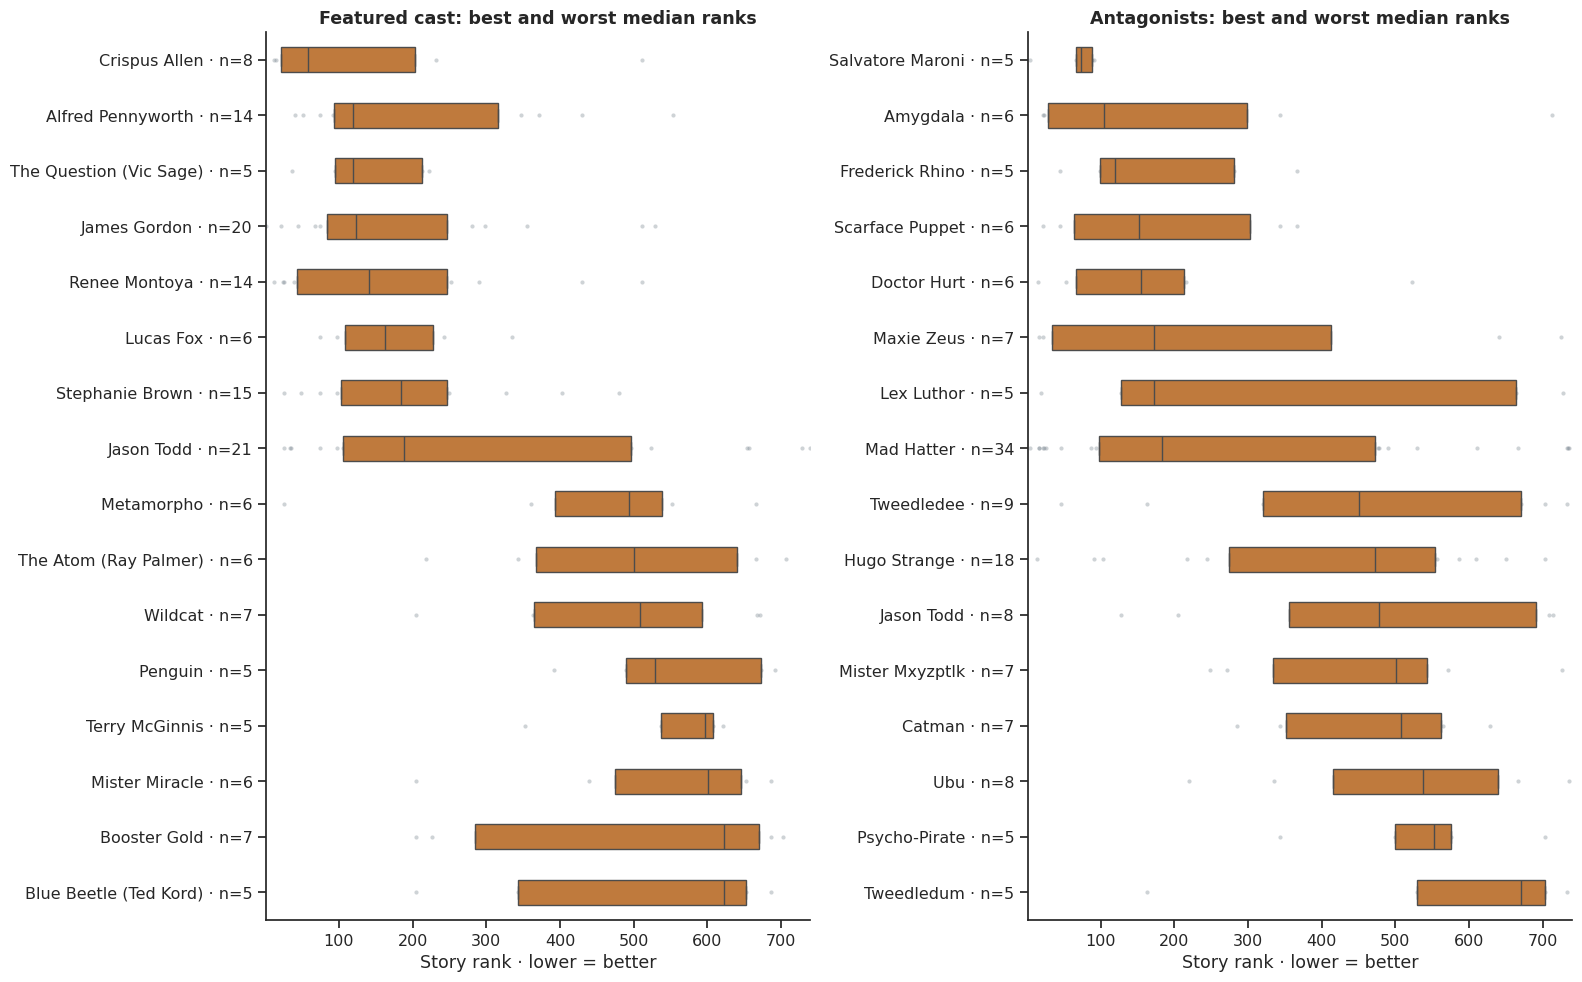

In [6]:
groups = {
    "Gotham City Police Department",
    "Batman Family",
    "Justice League of America",
    "Birds of Prey",
    "Justice League",
    "Outsiders",
    "Falcone Crime Family",
    "Vampires",
    "Man-Bat Commandos",
    "Gotham Organized Crime",
    "Dinosaurs",
    "Batman Villains",
    "Kobra Cult",
    "Nazi Party",
    "Secret Society of Super-Villains",
    "Court of Owls",
    "League of Assassins",
    "Zombies",
    "False Face Society",
    "Tweedledum and Tweedledee",
    "Regime",
    "Demons",
}
fig, axes = plt.subplots(1, 2, figsize=(16, 10), sharex=True)
for ax, (role, table) in zip(axes, profiles.items()):
    named = table[table.n.ge(5) & ~table.index.isin(groups)]
    extremes = pd.concat([named.head(8), named.tail(8)]).loc[lambda t: ~t.index.duplicated()]
    labels = extremes.display_name + " · n=" + extremes.n.astype(str)
    rank_boxes(ax, entries[role], "entity", labels, COLORS["orange"])
    ax.set_title(f"{role}: best and worst median ranks")
    display(
        collapsible(
            f"{role}: best- and worst-ranked examples",
            extremes[
                [
                    "display_name",
                    "n",
                    "median_rank",
                    "best_rank",
                    "best_story",
                    "worst_rank",
                    "worst_story",
                ]
            ].rename(
                columns={
                    "display_name": "Character",
                    "n": "Stories",
                    "median_rank": "Median rank",
                    "best_rank": "Best rank",
                    "best_story": "Best-ranked story",
                    "worst_rank": "Worst rank",
                    "worst_story": "Worst-ranked story",
                }
            ),
            "Lower is better. Best and worst refer to this character's stories.",
            index=False,
        )
    )
fig.tight_layout()
plt.show()

## Gorilla watch. Shark watch.

**The Joker's Five-Way Revenge** (#11) features a shark tank. **Three Jokers** (#740) features a Jokerized shark. That is quite a range.

These are checked sightings from the available synopses and cast lists, including cameos and flashbacks. King Shark, robots, and splicers get their own labels. Tiger Shark and Great White Shark are human villains, so they don't count. A story missing from the chart is unconfirmed, not animal-free.

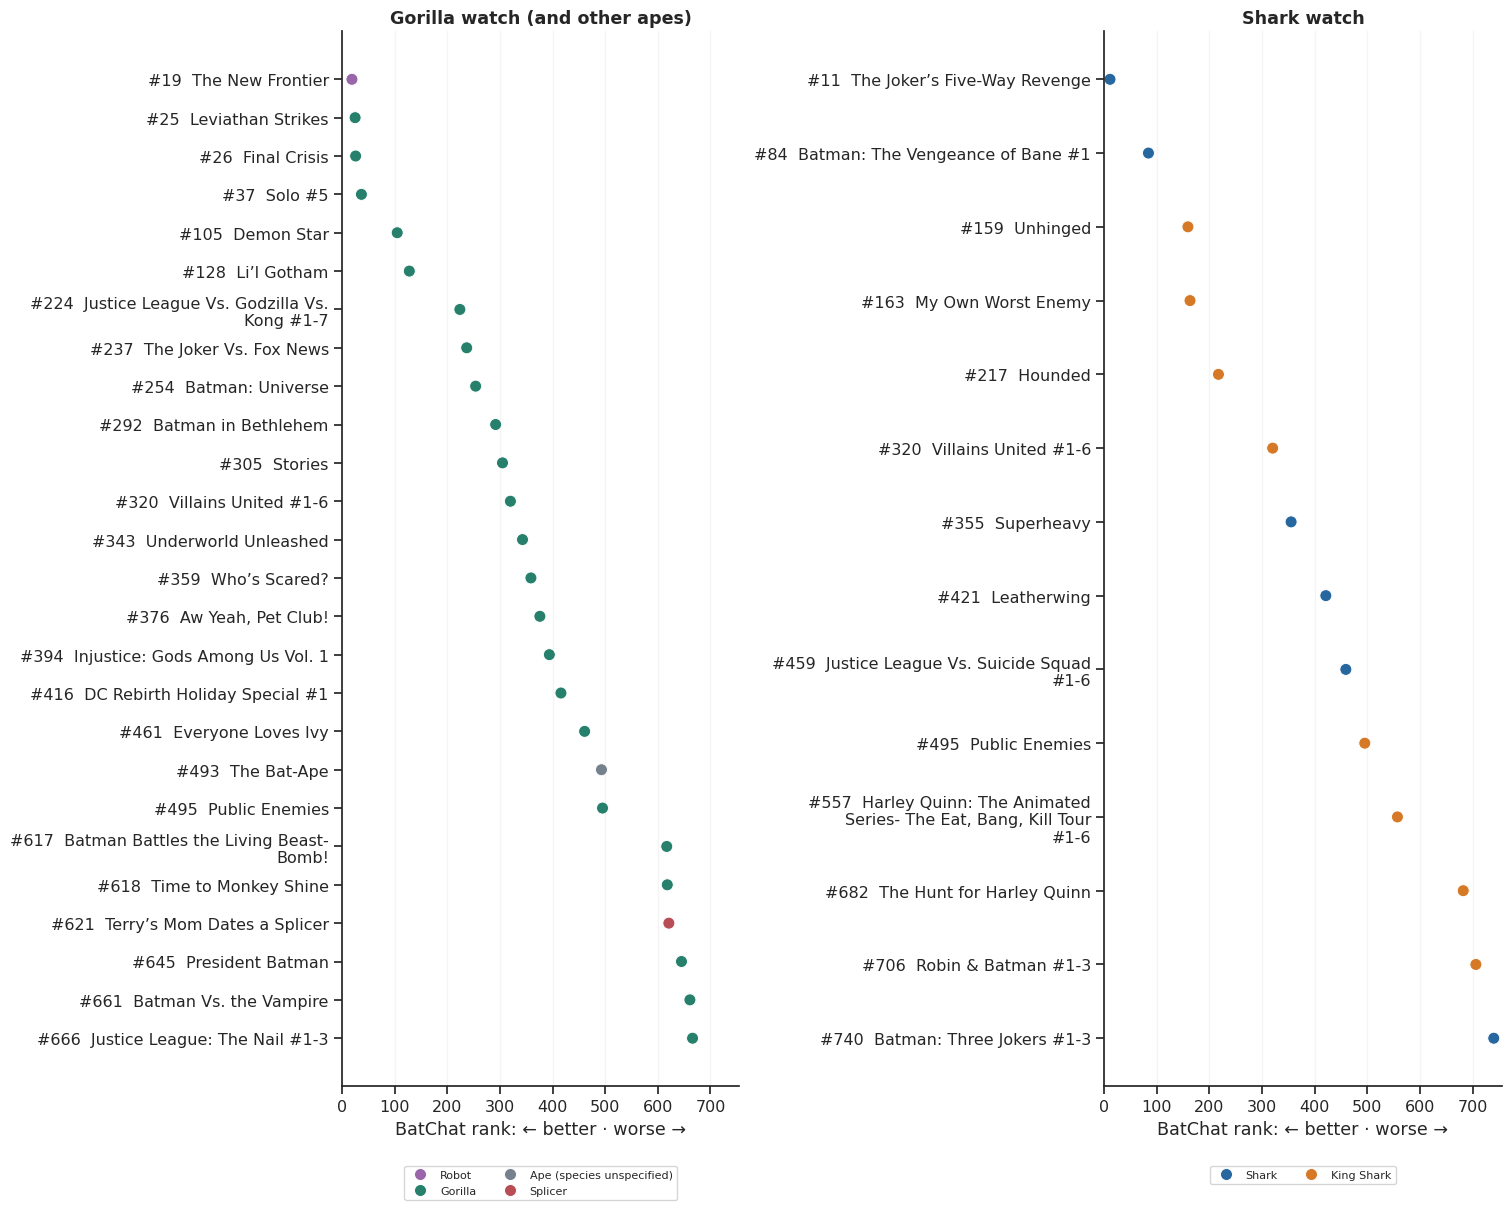

In [7]:
animal_watch = pd.read_csv(DATA / "animal_watch.csv")
kinds = {
    "gorilla": "Gorilla",
    "ape": "Ape (species unspecified)",
    "shark": "Shark",
    "shark_person": "King Shark",
    "robot": "Robot",
    "splicer": "Splicer",
}
sightings = (
    animal_watch[animal_watch.classification.isin(kinds)]
    .merge(stories[["story_id", "title", "rank"]], on="story_id", validate="many_to_one")
    .assign(kind=lambda d: d.classification.map(kinds))
)
# One point per story and animal family; keep the more specific identification.
sightings = sightings.sort_values(
    "classification", key=lambda x: x.map({"gorilla": 0, "ape": 1}).fillna(2)
)
sightings["family"] = sightings.animal.replace({"ape": "gorilla"})
sightings = sightings.drop_duplicates(["story_id", "family"]).sort_values("rank")
sightings["label"] = sightings["rank"].map("#{}".format) + "  " + sightings.title.str.wrap(32)

fig, axes = plt.subplots(1, 2, figsize=(15, 12), layout="constrained")
palette = dict(
    zip(kinds.values(), ["#26806B", "#75818C", "#2767A0", "#D57927", "#9966AA", "#B84D55"])
)
for ax, animals, title in zip(
    axes, [{"gorilla", "ape"}, {"shark"}], ["Gorilla watch (and other apes)", "Shark watch"]
):
    part = sightings[sightings.animal.isin(animals)]
    sns.scatterplot(data=part, x="rank", y="label", hue="kind", palette=palette, s=75, ax=ax)
    ax.set(title=title, xlabel="BatChat rank: ← better · worse →", ylabel="", xlim=(0, N + 15))
    ax.legend(title="", loc="upper center", bbox_to_anchor=(0.5, -0.07), fontsize=8, ncol=2)
    ax.grid(axis="x", alpha=0.2)
plt.show()

In **Superheavy** (#355), Gordon's robotic Batsuit uses two shark carcasses as clubs. That earns a mention here, if nothing else.

`animal_watch.csv` links every entry to its source and also records the false matches. There are too few consistently documented sightings to estimate a gorilla or shark advantage.

### Mad Hatter: a small role in a great book still counts

Mad Hatter has one of the best antagonist medians, but his advantage comes mostly from **ensemble books and collections**. The source lists **Jervis Tetch as an antagonist** in 34 ranked stories. We match that character ID, not "mad" in a title or summary.

But *The Long Halloween* (#4), *Dark Victory* (#16), and *Final Crisis* (#26) are not really Hatter stories, yet each contributes its full rank to his median. The same rule applies to Joker, Bane, Ra's al Ghul, and Two-Face:

,Antagonist,Stories,Median rank (lower = better),Highest-ranked book,Lowest-ranked book
0,Mad Hatter,34,183.5,The Long Halloween,Odyssey
1,Joker,112,296.5,The Long Halloween,Batman: Three Jokers #1-3
2,Bane,17,197.0,Knightfall Part 1: The Broken Bat,Odyssey
3,Ra's al Ghul,20,325.5,Tower of Babel,Odyssey
4,Two-Face,57,302.0,The Long Halloween,Batman: Three Jokers #1-3


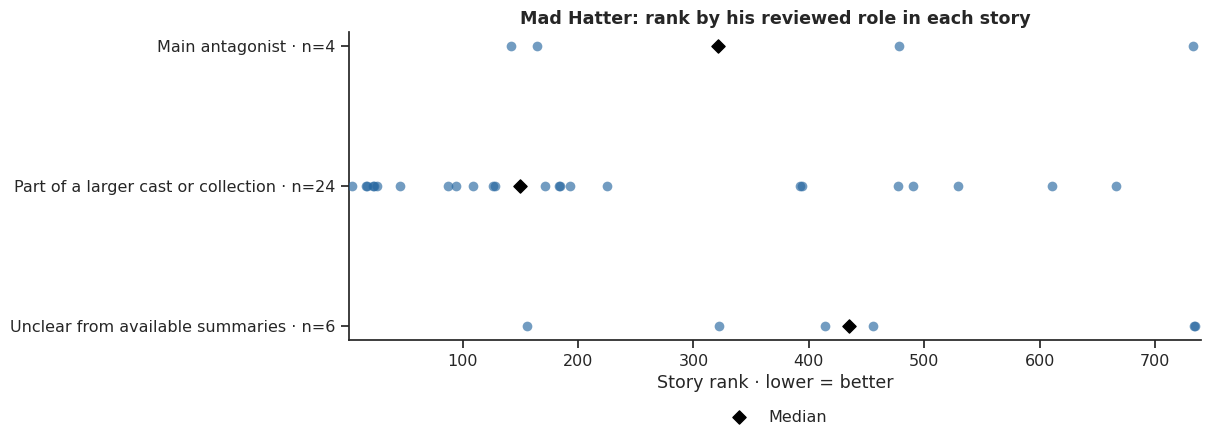

,Rank,Hatter-led story
0,142,Unknowing
1,164,Madness
2,478,The Scoop of the Century
3,733,Mad


In [8]:
compared_villains = ["Jervis Tetch", "Joker", "Bane", "Ra's al Ghul", "Harvey Dent"]
display(
    profiles["Antagonists"]
    .loc[compared_villains, ["display_name", "n", "median_rank", "best_story", "worst_story"]]
    .rename(
        columns={
            "display_name": "Antagonist",
            "n": "Stories",
            "median_rank": "Median rank (lower = better)",
            "best_story": "Highest-ranked book",
            "worst_story": "Lowest-ranked book",
        }
    )
    .reset_index(drop=True)
)

hatter_roles = pd.read_csv(DATA / "hatter_story_roles.csv")
role_order = [
    "Main antagonist",
    "Part of a larger cast or collection",
    "Unclear from available summaries",
]
role_summary = (
    hatter_roles.groupby("reviewed_role")["rank"]
    .agg(stories="size", median_rank="median")
    .reindex(role_order)
)

fig, ax = plt.subplots(figsize=(11, 4))
sns.stripplot(
    data=hatter_roles,
    x="rank",
    y="reviewed_role",
    order=role_order,
    color=COLORS["blue"],
    jitter=False,
    size=7,
    alpha=0.65,
    ax=ax,
)
ax.scatter(
    role_summary.median_rank, range(3), marker="D", color="black", s=45, label="Median", zorder=4
)
ax.set_yticks(range(3), [f"{role} · n={role_summary.loc[role, 'stories']}" for role in role_order])
ax.set(
    xlabel="Story rank · lower = better",
    ylabel="",
    xlim=(1, N),
    title="Mad Hatter: rank by his reviewed role in each story",
)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.18), frameon=False)
plt.show()
display(
    hatter_roles.loc[hatter_roles.reviewed_role.eq("Main antagonist"), ["rank", "title"]]
    .rename(columns={"rank": "Rank", "title": "Hatter-led story"})
    .reset_index(drop=True)
)

Reading the available summaries and story lists gives **four clearly Hatter-led stories**, with a median rank of **321**. The **24 ensemble or collection entries** have a median of **149.5**. Six remain unclear.

That explains most of the surprise. It does **not** show that Hatter-led stories beat Joker- or Bane-led ones; we haven't reviewed their roles the same way.

Source roles also need care. In *Escape to Blackgate*, Hatter helps Nightwing deceive Lock-Up, even though he is indexed as an antagonist. `hatter_story_roles.csv` records every decision, its uncertainty, and the source revisions.

### Is it the villain, or the era?

Separately, could **publication decade and story length** explain these averages? Each antagonist's stories are compared with other stories from the same decade and of similar length. This still counts any antagonist appearance, not just leading roles.

Orange dots show the average rank gap before grouping; blue dots show it afterward. **Negative means stories with that antagonist rank better.** Both use the same retained books.

<details><summary>How the comparison works</summary>

Length groups are 1, 2–4, and 5+ issues. Each decade/length group needs at least three stories with the antagonist and three without. We average the within-group gaps, weighted by the number of stories with the antagonist.

The counts beside the names show how many stories were retained. Requiring comparable books drops some cases: the League of Assassins keeps 12 of 26. Writers, other characters, and the hosts' choice of books remain uncontrolled. No significance test is implied.

</details>

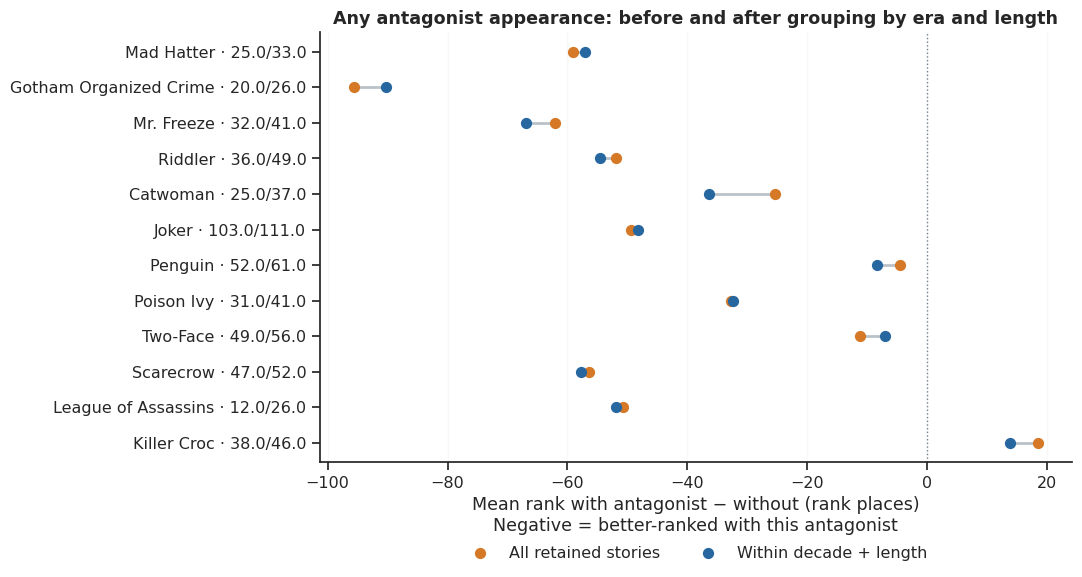

In [9]:
comparison = cast_known.dropna(subset=["decade"]).copy()
comparison["length_band"] = pd.cut(
    comparison.issue_count, [0, 1, 4, np.inf], labels=["1 issue", "2–4 issues", "5+ issues"]
)
comparison = comparison.dropna(subset=["length_band"])
frequent_antagonists = profiles["Antagonists"].nlargest(12, "n").sort_values("median_rank")
rows = []
for name in frequent_antagonists.index:
    present_ids = set(antagonists.loc[antagonists.entity.eq(name), "story_id"])
    sample = comparison.assign(present=comparison.story_id.isin(present_ids))
    retained, gaps, weights = [], [], []
    for _, chunk in sample.groupby(["decade", "length_band"], observed=True):
        present = chunk.loc[chunk.present, "rank"]
        absent = chunk.loc[~chunk.present, "rank"]
        if len(present) >= 3 and len(absent) >= 3:
            retained.append(chunk)
            gaps.append(present.mean() - absent.mean())
            weights.append(len(present))
    matched = pd.concat(retained)
    rows.append(
        {
            "entity": name,
            "available": int(sample.present.sum()),
            "retained": int(matched.present.sum()),
            "pooled_gap": matched.loc[matched.present, "rank"].mean()
            - matched.loc[~matched.present, "rank"].mean(),
            "within_gap": np.average(gaps, weights=weights),
        }
    )
era_check = pd.DataFrame(rows).set_index("entity")

fig, ax = plt.subplots(figsize=(11, 6))
positions = range(len(era_check))
for pos, row in zip(positions, era_check.itertuples()):
    ax.plot([row.pooled_gap, row.within_gap], [pos, pos], color="#BAC2C9", lw=2)
ax.scatter(
    era_check.pooled_gap,
    positions,
    color=COLORS["orange"],
    label="All retained stories",
    s=50,
    zorder=3,
)
ax.scatter(
    era_check.within_gap,
    positions,
    color=COLORS["blue"],
    label="Within decade + length",
    s=50,
    zorder=3,
)
ax.axvline(0, color=COLORS["grey"], ls=":", lw=1)
ax.set(
    yticks=positions,
    yticklabels=[
        f"{display_names.get(name, name)} · {row.retained}/{row.available}"
        for name, row in era_check.iterrows()
    ],
    xlabel="Mean rank with antagonist − without (rank places)\nNegative = better-ranked with this antagonist",
    title="Any antagonist appearance: before and after grouping by era and length",
)
ax.invert_yaxis()
ax.xaxis.grid(True, alpha=0.15)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=2, frameon=False)
fig.tight_layout()
plt.show()

Grouping by decade and length leaves Hatter's gap largely intact. That doesn't fix the ensemble problem: a small role in a highly ranked book still counts. These adjustments address era and issue count, not a character's contribution to the story.

## Which Batman series fare best?

*Gotham Central* follows Gotham's police. *Batman Adventures* brings the animated series to comics. *Legends of the Dark Knight* tells standalone Batman arcs. *Black and White* collects monochrome short stories.

Here are the twelve series with the most ranked stories. A story spanning several series appears in each. Volumes stay separate, because *Batman* has restarted at #1 more than once.

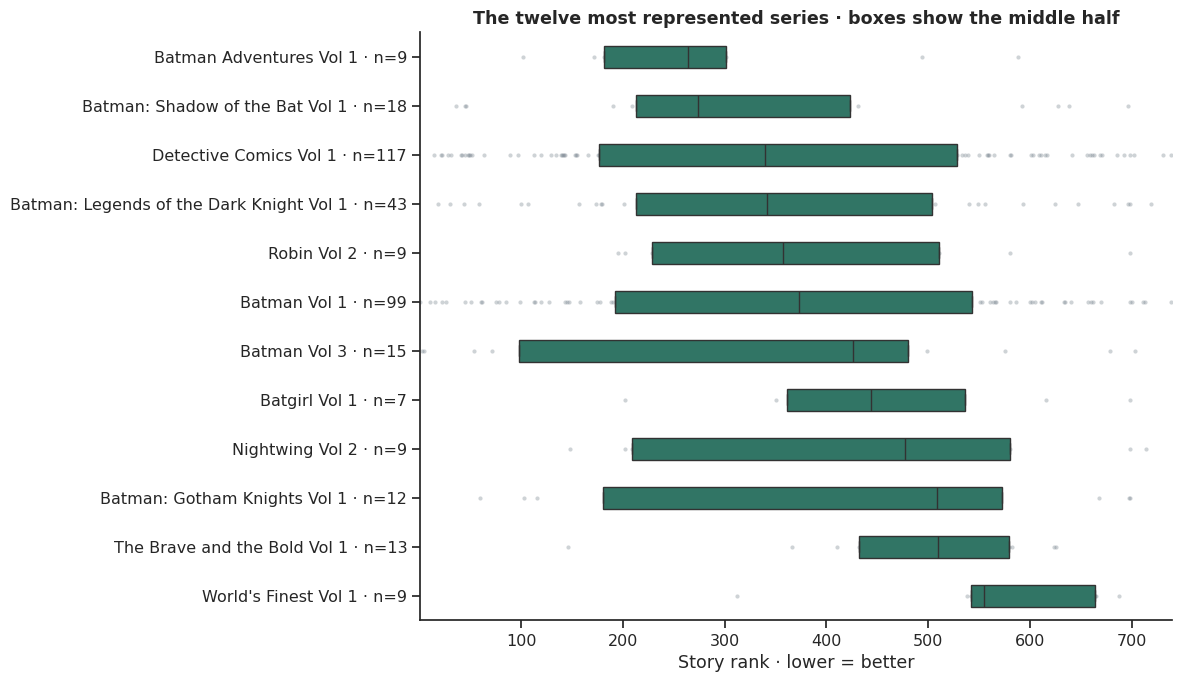

669 of 740 stories have a matched series title.


,Stories,Median rank,Best rank,Best story,Worst rank,Worst story
Series,,,,,,
Batman Annual Vol 3,5,58.0,7,Some Of These Days,341,Batman V.3 Annual #1
Gotham Central Vol 1,6,73.5,12,Soft Targets,194,Nature
Catwoman Vol 3,5,132.0,27,Anodyne,699,War Games
Batman and Robin Vol 1,5,152.0,70,Batman and Robin Must Die!,216,Batman Vs. Robin
Batman: Legends of the Dark Knight Halloween Special Vol 1,3,164.0,144,Choices/Fears,299,Ghosts
JLA Vol 1,6,165.0,43,Tower of Babel,604,Bouncing Baby Boy
Batman '66 Vol 1,4,166.0,126,Batman ’66 V.1,223,Batman ’66 V.3
Batman Chronicles Vol 1,4,182.5,117,Oracle: Year One- Born of Hope,365,Batman Chronicles #11
Batman Eternal Vol 1,3,184.0,77,Batman: Eternal Part 1,243,Batman: Eternal V.2


In [10]:
series_links = issues[["story_id", "wiki_title"]].dropna().copy()
series_links["Series"] = series_links.wiki_title.str.extract(r"^(.* Vol \d+) \d+[A-Za-z]?$")[0]
series_links = (
    series_links.dropna(subset=["Series"])
    .drop_duplicates(["story_id", "Series"])
    .merge(stories[["story_id", "rank", "title"]], on="story_id", validate="many_to_one")
)
series_rankings = (
    series_links.sort_values("rank")
    .groupby("Series")
    .agg(
        stories=("story_id", "nunique"),
        median_rank=("rank", "median"),
        best_rank=("rank", "first"),
        best_story=("title", "first"),
        worst_rank=("rank", "last"),
        worst_story=("title", "last"),
    )
)
top_series = series_rankings.nlargest(12, "stories").sort_values("median_rank")
fig, ax = plt.subplots(figsize=(12, 7))
rank_boxes(
    ax,
    series_links,
    "Series",
    top_series.index.to_series() + " · n=" + top_series.stories.astype(str),
    COLORS["green"],
)
ax.set_title("The twelve most represented series · boxes show the middle half")
fig.tight_layout()
plt.show()
print(f"{series_links.story_id.nunique()} of {N} stories have a matched series title.")

series_table = series_rankings[series_rankings.stories.ge(3)].sort_values("median_rank")
display(
    collapsible(
        f"All {len(series_table)} series with three or more ranked stories",
        series_table.rename(columns=lambda c: c.replace("_", " ").capitalize()),
        "Lower median rank is better. A cross-series story can appear in several rows.",
    )
)

### Elseworlds and graphic novels

**Elseworlds** stories put familiar characters in alternate continuities. **32 stories** contain an issue explicitly labeled Elseworlds, and the ranking list calls **26** of them original graphic novels. The two groups overlap.

The wiki also labels graphic novels, but that category can include collections, so we show it separately. Its labels describe the containing issue, which can include other stories. A missing label means unknown, so there is no clean "ordinary comics" comparison group.

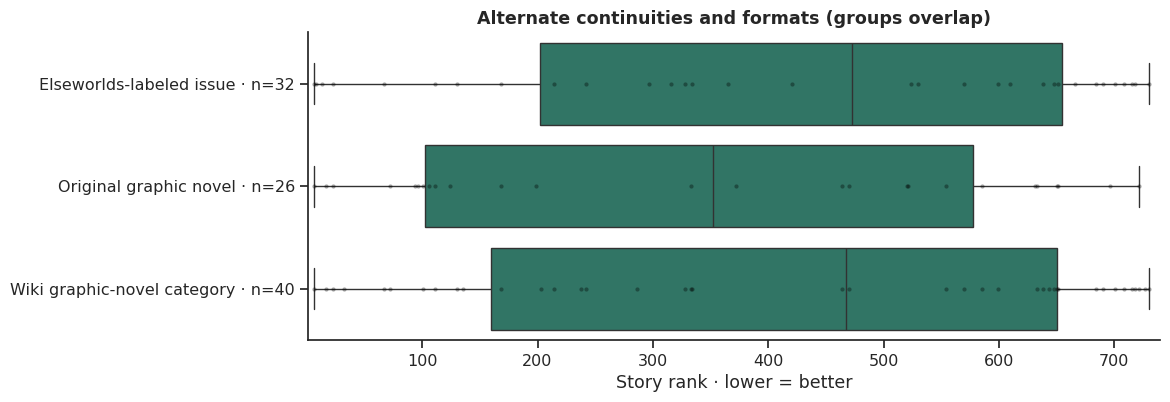

label,rank,title
Elseworlds-labeled issue,6,Batman/Dracula: Red Rain OGN
Elseworlds-labeled issue,8,The Dark Knight Returns
Elseworlds-labeled issue,13,Kingdom Come #1-4
Elseworlds-labeled issue,23,Batman: Crimson Mist OGN
Elseworlds-labeled issue,67,Batman: Gotham Noir
Elseworlds-labeled issue,111,Batman: Bloodstorm OGN
Elseworlds-labeled issue,130,Thrillkiller
Elseworlds-labeled issue,168,Batman: Nine Lives OGN
Elseworlds-labeled issue,214,Batman: Holy Terror
Elseworlds-labeled issue,242,Batman: Scar of the Bat


,stories,median_rank
event,,
Infinite Frontier,5,66.0
The New 52,4,67.0
Final Crisis,4,129.0
Batman R.I.P.,4,133.5
Return of Bruce Wayne,4,143.0
DC One Million,3,209.0
The Joker War,4,217.5
Batman: Reborn,7,219.0
Halloween,8,231.5


In [11]:
labels = pd.read_csv(DATA / "story_labels.csv")
label_books = stories.merge(labels, on="story_id", validate="one_to_one")
format_groups = {
    "Elseworlds-labeled issue": label_books.elseworlds_issue_count.gt(0),
    "Original graphic novel": label_books.format_hint.eq("original_graphic_novel"),
    "Wiki graphic-novel category": label_books.graphic_novel_issue_count.gt(0),
}
format_rows = pd.concat(
    [
        label_books.loc[mask, ["story_id", "title", "rank"]].assign(label=name)
        for name, mask in format_groups.items()
    ],
    ignore_index=True,
)
format_counts = format_rows.label.value_counts()
fig, ax = plt.subplots(figsize=(11, 4))
common = dict(data=format_rows, x="rank", y="label", order=list(format_groups), ax=ax)
sns.boxplot(**common, color=COLORS["green"], showfliers=False)
sns.stripplot(**common, color="black", alpha=0.35, jitter=False, size=3)
ax.set_yticks(
    range(len(format_groups)), [f"{name} · n={format_counts[name]}" for name in format_groups]
)
ax.set(
    xlabel="Story rank · lower = better",
    ylabel="",
    xlim=(1, N),
    title="Alternate continuities and formats (groups overlap)",
)
plt.show()
display(
    collapsible(
        "Labeled stories and their ranks",
        format_rows.sort_values(["label", "rank"])[["label", "rank", "title"]],
        index=False,
    )
)

# A named event can be a holiday special or a relaunch, so it is not a crossover flag.
events = label_books.loc[label_books.event_issue_count.gt(0), ["story_id", "rank", "event_names"]]
events = events.assign(event=events.event_names.str.split("|")).explode("event")
event_summary = events.groupby("event").agg(
    stories=("story_id", "nunique"), median_rank=("rank", "median")
)
display(
    collapsible(
        "Named events with at least three stories (not necessarily crossovers)",
        event_summary.query("stories >= 3").sort_values("median_rank"),
    )
)

## Do younger writers fare worse?

Stories by writers under 30 have a median rank of **484**, which suggests older writers do better. Then we split the group by decade:

- **1940s:** ten stories, median **543**.
- **1980s:** ten stories, median **141.5**.

Same age bracket, very different Batman comics. Read across a row to compare ages, or down a column to follow one age group through the decades. **Darker blue means better ranked.** Grey cells have fewer than five stories.

<details><summary>Calculating writer ages</summary>

The 512 included stories have complete issue lists and known ages for every writer. Age is the calendar-year difference for the issues each person wrote; co-written stories use the median. These are approximate ages, not birthdays matched to publication dates.

</details>

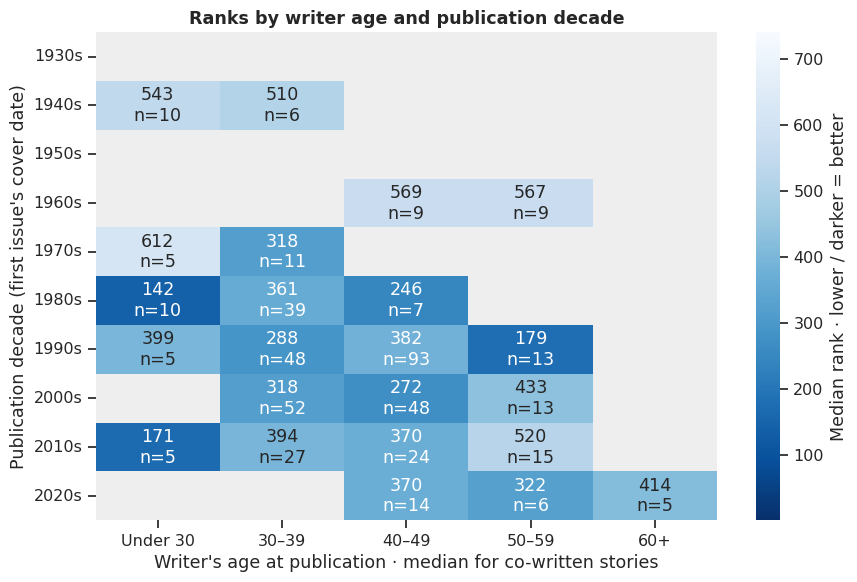

In [12]:
writer_age = (
    story_credits[story_credits.role.eq("writers")]
    .groupby("story_id")
    .agg(
        writers=("creator_id", "size"),
        known_ages=("age_at_publication_year_proxy", "count"),
        age=("age_at_publication_year_proxy", "median"),
    )
    .query("writers == known_ages")
    .merge(
        stories[
            [
                "story_id",
                "rank",
                "cover_year_start",
                "metadata_complete",
                "narrative_credit_issue_coverage",
            ]
        ],
        on="story_id",
        validate="one_to_one",
    )
)
writer_age = writer_age[
    writer_age.metadata_complete & writer_age.narrative_credit_issue_coverage.eq(1)
]
writer_age["age_band"] = pd.cut(
    writer_age.age, [-1, 29, 39, 49, 59, 110], labels=["Under 30", "30–39", "40–49", "50–59", "60+"]
)
writer_age["decade"] = (writer_age.cover_year_start // 10 * 10).astype(int)
age_profile = writer_age.groupby(["decade", "age_band"], observed=True)["rank"].agg(
    n="size", median="median"
)
medians = age_profile["median"].unstack("age_band")
counts = age_profile.n.unstack("age_band")

fig, ax = plt.subplots(figsize=(9, 6))
sns.heatmap(
    medians.where(counts.ge(5)),
    annot=medians.round().astype("Int64").astype(str) + "\nn=" + counts.astype("Int64").astype(str),
    fmt="",
    mask=counts.lt(5),
    vmin=1,
    vmax=N,
    cmap="Blues_r",
    ax=ax,
    yticklabels=[f"{year}s" for year in medians.index],
    cbar_kws={"label": "Median rank · lower / darker = better"},
)
ax.set_facecolor("#EEEEEE")
ax.set(
    xlabel="Writer's age at publication · median for co-written stories",
    ylabel="Publication decade (first issue's cover date)",
    title="Ranks by writer age and publication decade",
)
fig.tight_layout()
plt.show()

Writer age and publication era are tangled together here, and the sparse cells show how little evidence there is for comparing ages within some decades.

## Same writer, different comic

*Red Rain* ranks **#6**. *Unseen* ranks **#716**. Both are by **Doug Moench and Kelley Jones**.

The chart compares four writer–artist partnerships. Each dot is a story; each bar is a median. Even with both names fixed, there is plenty of room for a hit or a miss.

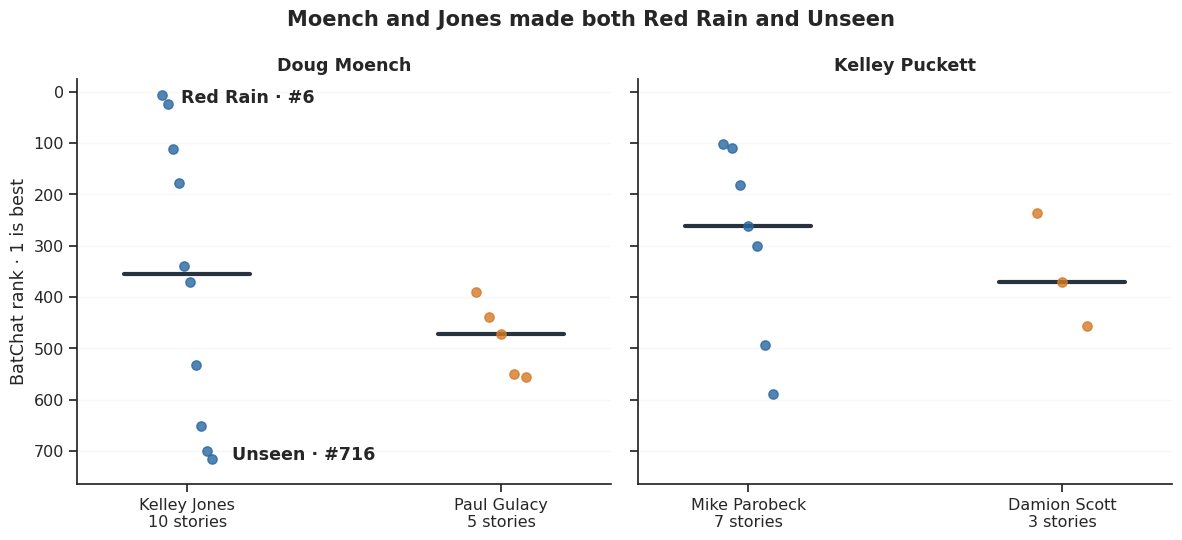

In [13]:
single_team = stories[
    stories.narrative_writers.map(split_set).map(len).eq(1)
    & stories.narrative_pencilers.map(split_set).map(len).eq(1)
    & stories.narrative_credit_issue_coverage.eq(1)
]
pairs = {
    "Doug Moench": ["Kelley Jones", "Paul Gulacy"],
    "Kelley Puckett": ["Mike Parobeck", "Damion Scott"],
}
fig, axes = plt.subplots(1, 2, figsize=(12, 5.5), sharey=True)
for ax, (writer, artists) in zip(axes, pairs.items()):
    for pos, artist in enumerate(artists):
        ranks = (
            single_team.loc[
                single_team.narrative_writers.eq(writer)
                & single_team.narrative_pencilers.eq(artist),
                "rank",
            ]
            .sort_values()
            .to_numpy()
        )
        x = pos + np.linspace(-0.08, 0.08, len(ranks))
        ax.scatter(
            x, ranks, s=45, alpha=0.8, color=[COLORS["blue"], COLORS["orange"]][pos], zorder=3
        )
        ax.plot([pos - 0.2, pos + 0.2], [np.median(ranks)] * 2, color="#273440", lw=3)
        if artist == "Kelley Jones":
            for k, label, offset in [
                (0, "Red Rain · #6", (14, -2)),
                (-1, "Unseen · #716", (14, 3)),
            ]:
                ax.annotate(
                    label,
                    (x[k], ranks[k]),
                    xytext=offset,
                    textcoords="offset points",
                    va="center",
                    fontweight="bold",
                )
    ax.set(
        xticks=[0, 1],
        xticklabels=[
            f"{artist}\n{(single_team.narrative_writers.eq(writer) & single_team.narrative_pencilers.eq(artist)).sum()} stories"
            for artist in artists
        ],
        title=writer,
        xlim=(-0.35, 1.35),
    )
    ax.yaxis.grid(True, alpha=0.15)
axes[0].set(ylabel="BatChat rank · 1 is best", ylim=(N + 25, -25))
fig.suptitle("Moench and Jones made both Red Rain and Unseen", fontweight="bold")
fig.tight_layout()
plt.show()

Kelley Puckett's books with Mike Parobeck have a median rank of **261 across seven stories**. With Damion Scott, it's **371 across three**.

But Parobeck's books belong to the world of *Batman: The Animated Series*, while Scott's include Cassandra Cain's early *Batgirl* stories and her introduction in *No Man's Land*. The artist, the protagonist, and the kind of comic all change together, so calling the difference "artist quality" would miss the point. [DC on Batman Adventures](https://www.dc.com/graphic-novels/batman-adventures-1992/batman-adventures-vol-2) · [DC on Scott and Cassandra Cain](https://www.dc.com/blog/2023/02/23/power-on-page-six-dc-comics-by-black-creators)

### Does keeping one team help an arc?

An artist change halfway through a story can be jarring. Arcs with the same writers and pencilers throughout have a median rank of **316.5**, versus **340** for arcs whose team changes.

Longer arcs have more chances to change artists, so we split by length. Stable teams rank about **30 places better at 3–4 issues**, **5 better at 5–6**, and **6 worse at 7+**. The dots tell the bigger story: both groups span most of the ranking. Black bars show medians.

<details><summary>Which arcs qualify?</summary>

At least three issues, a complete issue list, one selected story per issue, and known writers and pencilers throughout. "One team" means the same set of those people in every issue.

</details>

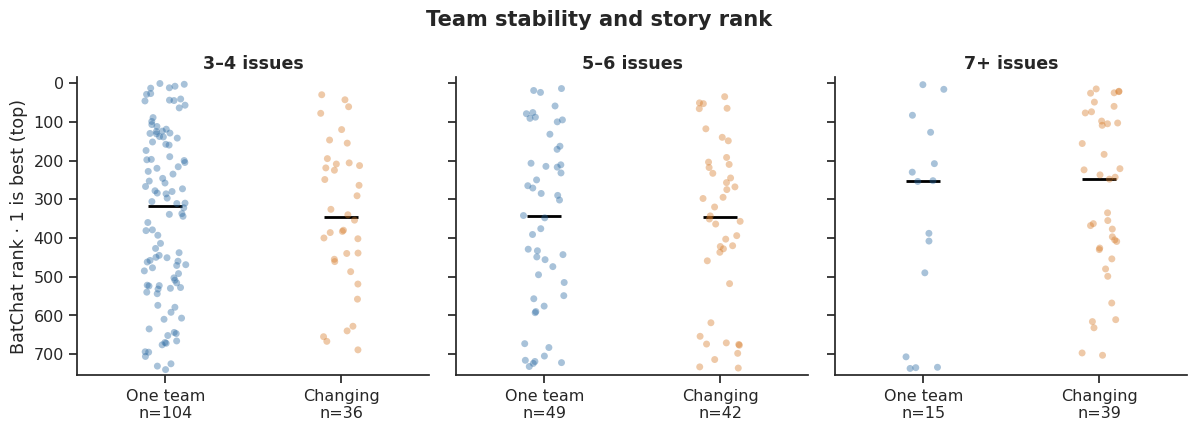

In [14]:
multi_story_issues = issues.selected_substory_indexes.fillna("").str.contains("|", regex=False)
teams = stories[
    stories.issue_count.ge(3)
    & ~stories.story_id.isin(issues.loc[multi_story_issues, "story_id"])
    & stories.metadata_complete
    & stories.narrative_credit_issue_coverage.eq(1)
].copy()
teams["stable_team"] = teams.narrative_dominant_team_share.eq(1)
teams["length_band"] = pd.cut(
    teams.issue_count, [2, 4, 6, np.inf], labels=["3–4 issues", "5–6 issues", "7+ issues"]
)
team_counts = teams.groupby(["length_band", "stable_team"], observed=True).size()

np.random.seed(42)  # fixes the strip-plot jitter
g = sns.catplot(
    data=teams,
    x="stable_team",
    y="rank",
    col="length_band",
    order=[True, False],
    hue="stable_team",
    legend=False,
    palette={True: COLORS["blue"], False: COLORS["orange"]},
    kind="strip",
    sharex=False,
    jitter=0.12,
    alpha=0.4,
    height=4.5,
    aspect=0.9,
)
g.map_dataframe(
    sns.pointplot,
    x="stable_team",
    y="rank",
    order=[True, False],
    estimator="median",
    errorbar=None,
    markers="_",
    linestyles="none",
    color="black",
    markersize=24,
)
g.set(ylim=(N + 15, -15)).set_axis_labels("", "BatChat rank · 1 is best (top)").set_titles(
    "{col_name}"
)
for ax, band in zip(g.axes.flat, teams.length_band.cat.categories):
    n = team_counts.loc[band].reindex([True, False])
    ax.set_xticks([0, 1], [f"One team\nn={n[True]}", f"Changing\nn={n[False]}"])
g.figure.subplots_adjust(top=0.82)
g.figure.suptitle("Team stability and story rank", y=0.97, fontweight="bold")
plt.show()

### The names that recur across runs

John Costanza and Todd Klein lead the lettering credits, and Adrienne Roy leads color. These names connect books that fans usually discuss by writer or penciler.

Across the same **589 stories**, the five most frequent letterers hold **34.6%** of lettering assignments. The equivalent shares are **18.3%** for writers and **9.5%** for pencilers.

<details><summary>Counting shared assignments</summary>

Each story contributes one unit per role, split equally among its contributors; two writers get half each. All 589 stories have all six roles recorded. Studios are included. These shares describe this list, not industry employment or working hours.

</details>

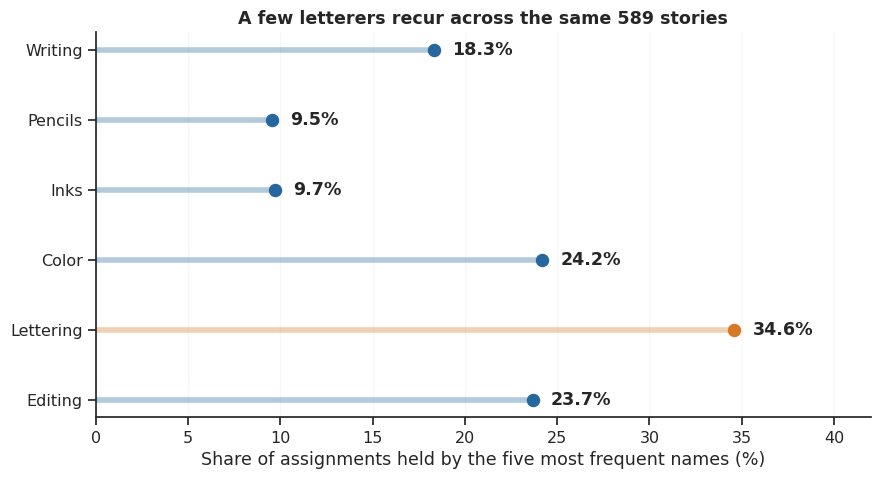

,Name,Stories
Role,,
Writing,Chuck Dixon,33
Writing,Alan Grant,30
Pencils,Kelley Jones,15
Pencils,Norm Breyfogle,17
Inks,Rick Burchett,17
Inks,Steve Mitchell,14
Color,Adrienne Roy,66
Color,Dave Stewart,27
Lettering,John Costanza,69


In [15]:
role_links = story_credits[story_credits.story_id.isin(fully_credited)].copy()
roles_per_story = role_links.groupby("story_id").role.nunique()
role_links = role_links[
    role_links.story_id.isin(roles_per_story.index[roles_per_story.eq(len(ROLES))])
]
role_links["credit_share"] = 1 / role_links.groupby(["story_id", "role"]).creator_id.transform(
    "size"
)
n_complete = role_links.story_id.nunique()
credit_counts = (
    role_links.groupby(["role", "creator_id"])
    .agg(readings=("story_id", "nunique"), share=("credit_share", "sum"))
    .reset_index()
    .merge(creators[["creator_id", "name"]], on="creator_id", validate="many_to_one")
    .assign(share=lambda d: d.share / n_complete)
    .sort_values("share", ascending=False)
)
top_five_share = credit_counts.groupby("role").head(5).groupby("role").share.sum().reindex(ROLES)
role_labels = {
    "writers": "Writing",
    "pencilers": "Pencils",
    "inkers": "Inks",
    "colorists": "Color",
    "letterers": "Lettering",
    "editors": "Editing",
}
fig, ax = plt.subplots(figsize=(10, 5))
for pos, (role, share) in enumerate(top_five_share.items()):
    color = COLORS["orange"] if role == "letterers" else COLORS["blue"]
    ax.hlines(pos, 0, 100 * share, color=color, lw=4, alpha=0.35)
    ax.scatter(100 * share, pos, s=75, color=color, zorder=3)
    ax.text(100 * share + 1, pos, f"{100 * share:.1f}%", va="center", fontweight="bold")
ax.set(
    yticks=range(len(ROLES)),
    yticklabels=[role_labels[r] for r in ROLES],
    xlim=(0, 42),
    xlabel="Share of assignments held by the five most frequent names (%)",
    title=f"A few letterers recur across the same {n_complete} stories",
)
ax.invert_yaxis()
ax.xaxis.grid(True, alpha=0.15)
plt.show()
top_names = credit_counts.groupby("role").head(2)
display(
    top_names.assign(Role=top_names.role.map(role_labels))
    .rename(columns={"name": "Name", "readings": "Stories"})[["Role", "Name", "Stories"]]
    .set_index("Role")
    .loc[list(role_labels.values())]
)

## Same length, different ways to tell a story

*Undone* uses **20 silent pages**. *The Clown at Midnight* uses **22 pages of illustrated prose**. They rank **47th and 85th**: similar lengths, very different reading experiences. [DC on the silent issue](https://www.dc.com/blog/2013/09/05/5-2-reasons-dc-comics-the-new-52-anniversary-edition)

A wiki summary can describe a silent image at length or squeeze pages of dialogue into a sentence. Its word count doesn't measure how wordy the comic is.

### What a plot summary can't show you

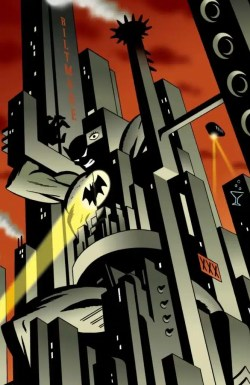

Batman almost disappears into the angular black shapes of Gotham. The orange sky separates the towers, and a yellow beam pulls the eye diagonally across the scene.

"Batman above Gotham" captures the subject but loses the composition.

Color also depends on the edition. Richmond Lewis colored *Year One* twice, for different presentations. Studying that difference would require knowing which version the hosts read. [DC on Richmond Lewis](https://www.dc.com/blog/2024/03/29/the-woman-whose-colors-brought-batman-year-one-to-life-twice)

*Darwyn Cooke artwork for Ego, © DC. Small image reproduced by [ComicsXF](https://comicsxf.com/batchat-rankings/); [image source](https://i0.wp.com/www.comicsxf.com/wp-content/uploads/2022/06/batman-ego-666x1024.webp?resize=640%2C984). Included for the visual commentary above.*

## What do the plots sound like?

We have **1,711 uncapped summaries** totaling **703,219 words**. **587 stories** have some text, and **481** have every selected summary plus a complete issue list.

Before looking at the words, check which books they represent. The 1980s have complete text for **59 of 69** stories; the 2020s for just **8 of 69**. Any text analysis will mostly describe older books.

Green means complete, orange partial, and grey no usable text. The numbers count stories. [Can we predict BatChat's favorites?](https://www.kaggle.com/code/danofer/batchat-s-favorite-batman-stories) tests whether these words improve rank predictions.

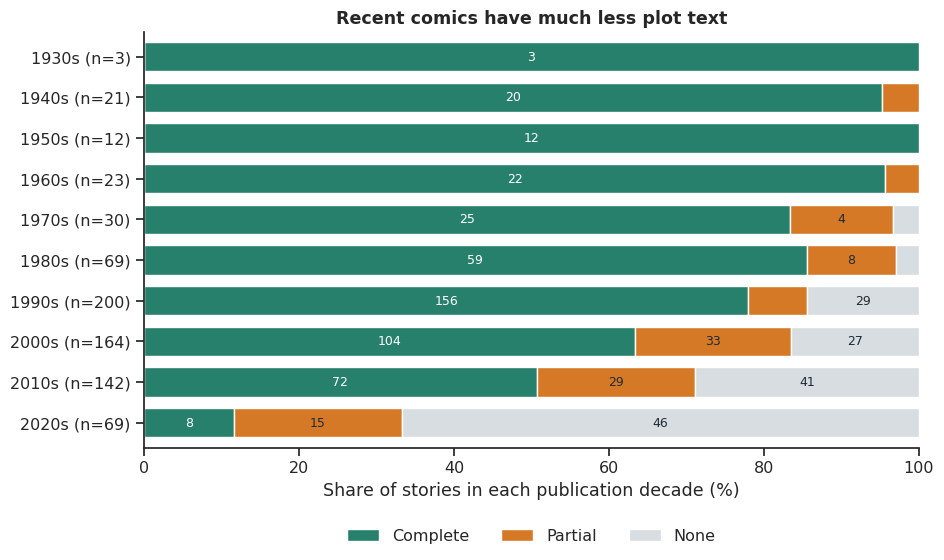

7 stories have no known decade and are not shown.


In [16]:
texts = pd.read_csv(DATA / "story_texts.csv")
available = texts[texts.text_status.eq("available")].copy()
# Identical summaries (ignoring case and spacing) count once per story.
available["text_key"] = available.synopsis_text.str.casefold().str.split().str.join(" ")
plot_text = (
    available.drop_duplicates(["story_id", "text_key"])
    .groupby("story_id")
    .synopsis_text.agg("\n\n".join)
)
text_profile = stories[["story_id", "title", "rank", "cover_year_start"]].assign(
    plot_text=stories.story_id.map(plot_text).fillna(""),
    has_text=stories.story_id.isin(available.story_id),
    # Complete: every selected summary is available and the issue list is complete.
    complete=stories.story_id.map(
        texts.groupby("story_id").text_status.apply(lambda v: v.eq("available").all())
    )
    & stories.issue_list_complete,
)
text_profile["coverage"] = np.select(
    [text_profile.complete, text_profile.has_text], ["Complete", "Partial"], default="None"
)
text_profile["decade"] = (text_profile.cover_year_start // 10 * 10).astype("Int64")
coverage_order = ["Complete", "Partial", "None"]
text_by_era = pd.crosstab(text_profile.decade, text_profile.coverage)[coverage_order]
shares = 100 * text_by_era.div(text_by_era.sum(axis=1), axis=0)

fig, ax = plt.subplots(figsize=(10, 5.4))
shares.plot.barh(
    stacked=True, color=[COLORS["green"], COLORS["orange"], "#D8DDE1"], width=0.72, ax=ax
)
for bars, status in zip(ax.containers, coverage_order):
    labels = [str(n) if share >= 9 else "" for n, share in zip(text_by_era[status], shares[status])]
    ax.bar_label(
        bars,
        labels=labels,
        label_type="center",
        fontsize=9,
        color="white" if status == "Complete" else "#202B35",
    )
ax.set(
    yticklabels=[f"{decade}s (n={n})" for decade, n in text_by_era.sum(axis=1).items()],
    xlim=(0, 100),
    xlabel="Share of stories in each publication decade (%)",
    ylabel="",
    title="Recent comics have much less plot text",
)
ax.invert_yaxis()
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=3, frameon=False)
plt.show()
print(f"{text_profile.decade.isna().sum()} stories have no known decade and are not shown.")

### Vampires, nightmares, and other plot ingredients

Vampires turn up in **nine fully summarized stories**, from *Red Rain* (#6) to *Superman and Batman vs. Vampires and Werewolves* (#732). The same premise leaves plenty of room in execution.

These are keyword searches, not hand-labeled themes, so a dream can be a passing remark. Each dot is one story. We use the 481 stories with complete summaries; longer summaries have more chances to match.

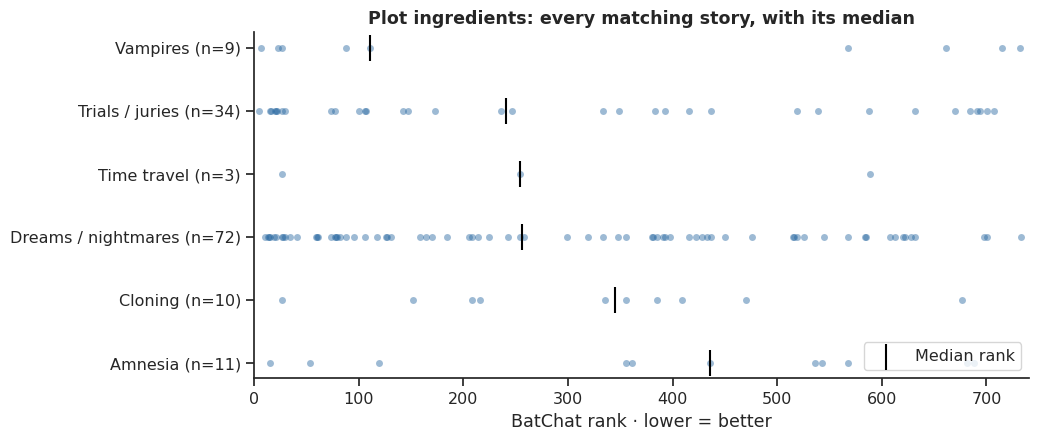

,Stories,Median rank,Highest-ranked story,Lowest-ranked story
topic,,,,
Vampires,9,111.0,Batman/Dracula: Red Rain OGN,Superman and Batman Vs. Vampires and Werewolves
Trials / juries,34,241.0,The Long Halloween,Identity Crisis
Time travel,3,254.0,Final Crisis,DCU Infinite Holiday Special #1
Dreams / nightmares,72,256.0,Batman: Black and White Vol.1,Mad
Cloning,10,345.0,Final Crisis,The Amazo Virus
Amnesia,11,436.0,Batman: R.I.P.,Superman’s Secret Kingdom


In [17]:
plot_terms = {
    "Vampires": r"\bvampir\w*",
    "Dreams / nightmares": r"\b(?:dreams?|nightmares?)\b",
    "Amnesia": r"\b(?:amnesia|amnesiac)\b",
    "Time travel": r"\btime[- ]trav\w*",
    "Trials / juries": r"\b(?:trial|jury|courtroom)\b",
    "Cloning": r"\bclon(?:e[sd]?|ing)\b",
}
complete_plots = text_profile[text_profile.complete].reset_index(drop=True)
term_matches = pd.concat(
    [
        complete_plots.loc[
            complete_plots.plot_text.str.contains(pattern, case=False), ["title", "rank"]
        ].assign(topic=topic)
        for topic, pattern in plot_terms.items()
    ],
    ignore_index=True,
)
term_summary = (
    term_matches.sort_values("rank")
    .groupby("topic")
    .agg(
        stories=("title", "size"),
        median_rank=("rank", "median"),
        highest_ranked=("title", "first"),
        lowest_ranked=("title", "last"),
    )
    .sort_values("median_rank")
)
fig, ax = plt.subplots(figsize=(10, 4.5))
sns.stripplot(
    data=term_matches,
    x="rank",
    y="topic",
    order=term_summary.index,
    jitter=False,
    alpha=0.45,
    color=COLORS["blue"],
    ax=ax,
)
ax.scatter(
    term_summary.median_rank,
    range(len(term_summary)),
    marker="|",
    s=350,
    color="black",
    label="Median rank",
    zorder=4,
)
ax.set_yticks(range(len(term_summary)), [f"{k} (n={n})" for k, n in term_summary.stories.items()])
ax.set(
    xlim=(0, N + 1),
    xlabel="BatChat rank · lower = better",
    ylabel="",
    title="Plot ingredients: every matching story, with its median",
)
ax.legend(loc="lower right")
plt.show()
term_summary.rename(
    columns={
        "stories": "Stories",
        "median_rank": "Median rank",
        "highest_ranked": "Highest-ranked story",
        "lowest_ranked": "Lowest-ranked story",
    }
)

### Gotham without "Batman"

The bat below is built from the words in the **481 completely summarized stories**. Larger words appear in more stories; repeating a word within one story adds nothing.

We remove common English words and a short list of character and place names, so the names don't crowd out everything else. **Rankings play no part in these clouds.**

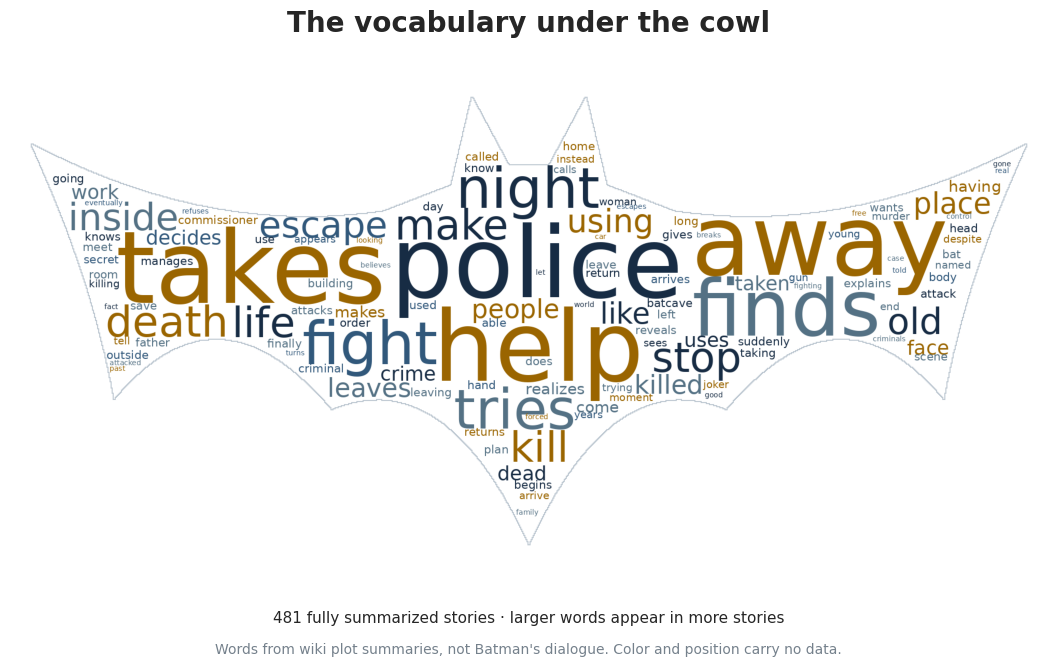

In [18]:
from matplotlib.colors import ListedColormap
from matplotlib.font_manager import findfont
from matplotlib.path import Path as ShapePath
from PIL import Image, ImageDraw, ImageFont
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS, CountVectorizer
from wordcloud import WordCloud

extra_stopwords = set(
    """batman bruce wayne gotham city robin dick grayson tim drake
    jason todd alfred gordon riddler edward nashton nigma nygma penguin oswald cobblepot
    tells says asks comes goes gets just later soon new man men time way back
    couldn didn doesn isn wasn wouldn don ve ll aren weren hasn hadn haven shouldn needn mustn mightn won shan""".split()
)
vectorizer = CountVectorizer(
    binary=True,
    min_df=3,
    stop_words=sorted(ENGLISH_STOP_WORDS | extra_stopwords),
    token_pattern=r"(?u)\b[a-zA-Z]{3,}\b",
)
word_presence = vectorizer.fit_transform(complete_plots.plot_text)  # stories × words, 1 = present
terms = vectorizer.get_feature_names_out()
story_counts = pd.Series(word_presence.sum(axis=0).A1, index=terms)

# Simple drawn silhouettes (a bat, a question mark, an umbrella) as cloud masks; 0 = draw here.
bat_outline = ShapePath(
    [(20, 90), (190, 180), (360, 155), (425, 130), (445, 45), (480, 110), (520, 110), (555, 45),
     (575, 130), (640, 155), (810, 180), (980, 90), (920, 220), (900, 335), (800, 215), (690, 345),
     (580, 300), (500, 475), (420, 300), (310, 345), (200, 215), (100, 335), (80, 220), (20, 90), (20, 90)],
    [1, 3, 3, 2, 2, 2, 2, 2, 2, 2, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 79],
)  # fmt: skip
yy, xx = np.mgrid[:520, :1000]
inside = bat_outline.contains_points(np.column_stack([xx.ravel(), yy.ravel()])).reshape(xx.shape)
question = Image.new("L", (600, 600), 255)
draw = ImageDraw.Draw(question)
font = ImageFont.truetype(findfont("DejaVu Sans:weight=bold"), 780)
x0, y0, x1, y1 = draw.textbbox((0, 0), "?", font=font)
draw.text(((600 - x1 + x0) / 2 - x0, (600 - y1 + y0) / 2 - y0), "?", font=font, fill=0)
umbrella = Image.new("L", (600, 600), 255)
draw = ImageDraw.Draw(umbrella)
draw.pieslice((20, 60, 580, 620), 180, 360, fill=0)
draw.rectangle((280, 300, 325, 455), fill=0)
draw.arc((185, 385, 325, 525), 0, 180, fill=0, width=45)
masks = {
    "Bat": np.where(inside, 0, 255).astype("uint8"),
    "Riddler": np.where(np.array(question) < 128, 0, 255).astype("uint8"),
    "Penguin": np.array(umbrella),
}
font_path = findfont("DejaVu Sans")


def word_cloud(frequencies, mask, colors, max_words):
    return WordCloud(
        mask=mask,
        background_color="white",
        font_path=font_path,
        random_state=42,
        max_words=max_words,
        scale=2,
        prefer_horizontal=1,
        colormap=ListedColormap(colors),
        contour_width=1,
        contour_color="#BBC6D0",
    ).generate_from_frequencies(frequencies)


common_words = story_counts.sort_index().sort_values(ascending=False, kind="stable").head(120)
fig, ax = plt.subplots(figsize=(12, 6.8))
ax.imshow(
    word_cloud(
        common_words.to_dict(), masks["Bat"], ["#172C44", "#31587B", "#9A6500", "#547184"], 120
    )
)
ax.axis("off")
ax.set_title("The vocabulary under the cowl", fontsize=20, pad=14)
fig.text(
    0.5,
    0.10,
    f"{len(complete_plots)} fully summarized stories · larger words appear in more stories",
    ha="center",
    fontsize=11,
)
fig.text(
    0.5,
    0.055,
    "Words from wiki plot summaries, not Batman's dialogue. Color and position carry no data.",
    ha="center",
    fontsize=10,
    color=COLORS["grey"],
)
fig.tight_layout(rect=(0, 0.12, 1, 1))
plt.show()

### Riddler's puzzles, Penguin's business

"Takes," "away," and "finds" are the language of retelling a plot. "Police," "death," and "escape" feel more like Gotham. Which words set particular villains apart?

Below, larger words are **more common in that villain's stories than in the rest**. A word must appear in at least five stories with that villain as an antagonist.

<details><summary>How the comparison works</summary>

We merge Riddler's Nashton, Nigma, and Nygma names, and Penguin's named and generic entries. Ensemble appearances count. Both groups need complete plot and cast records.

Word size is the log2 ratio of how often the word appears in each group, after adding one to the word counts and two to the group sizes so rare words don't dominate. A score of 1 means twice as common. Only positive scores appear. Each cloud has its own scale; color and position carry no information. [WordCloud documentation](https://amueller.github.io/word_cloud/generated/wordcloud.WordCloud.html)

</details>

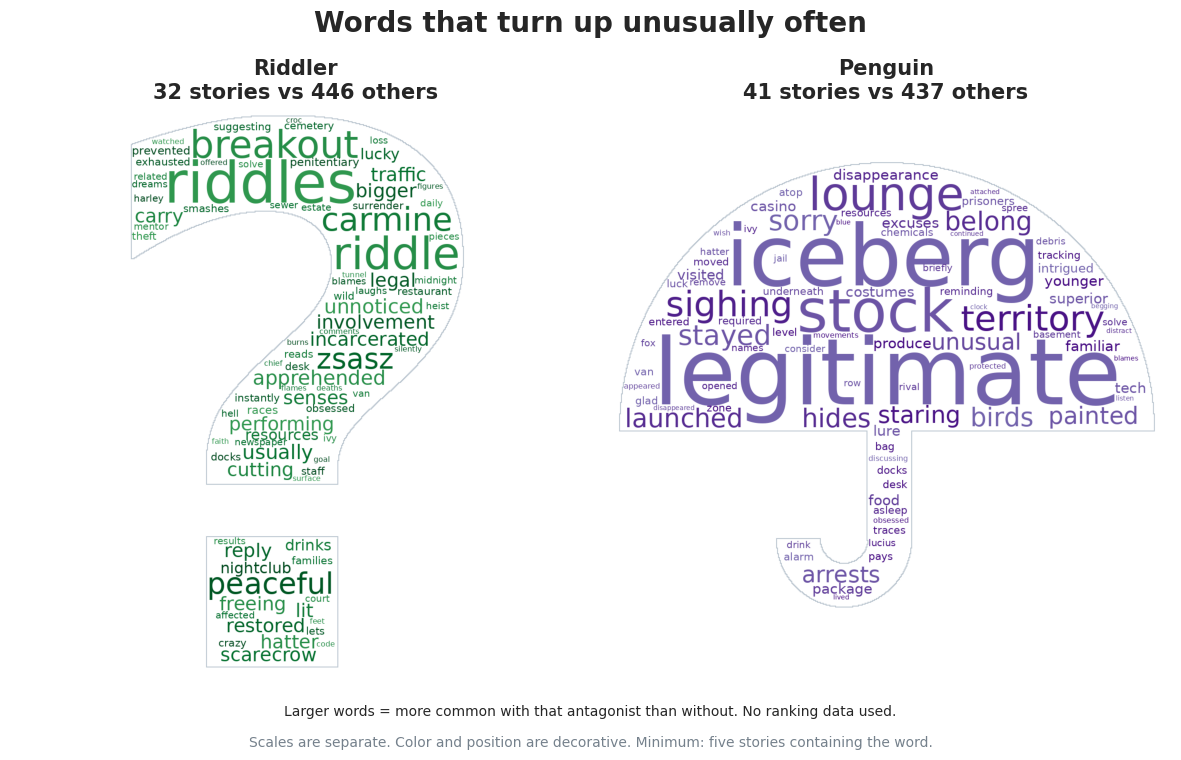

,Antagonist,Word,With this antagonist,Other stories
0,Riddler,riddle,15 / 32,4 / 446
1,Riddler,scarecrow,12 / 32,16 / 446
2,Penguin,legitimate,5 / 41,0 / 437
3,Penguin,iceberg,11 / 41,3 / 437


In [19]:
cloud_stories = stories.set_index("story_id").reindex(complete_plots.story_id)
has_cast = (
    cloud_stories.cast_scope.eq("selected_narratives") & cloud_stories.cast_issue_coverage.eq(1)
).to_numpy()
cloud_antagonists = cloud_stories.antagonists_entity_ids.map(split_set).map(
    lambda values: {re.sub(r" \([^()]+\)$", "", value) for value in values}
)
cohorts = {
    "Riddler": {"Edward Nashton", "Edward Nigma", "Edward Nygma", "J. Edward Nygma", "Riddler"},
    "Penguin": {"Oswald Cobblepot", "Penguin"},
}
cloud_terms = []
fig, axes = plt.subplots(1, 2, figsize=(12, 7.8))
for ax, (villain, names), palette in zip(axes, cohorts.items(), ["Greens", "Purples"]):
    present = cloud_antagonists.map(lambda values: bool(values & names)).to_numpy() & has_cast
    other = has_cast & ~present
    counts = word_presence[present].sum(axis=0).A1
    other_counts = word_presence[other].sum(axis=0).A1
    score = np.log2(((counts + 1) / (present.sum() + 2)) / ((other_counts + 1) / (other.sum() + 2)))
    table = pd.DataFrame(
        {
            "villain": villain,
            "term": terms,
            "with": counts,
            "with_total": present.sum(),
            "other": other_counts,
            "other_total": other.sum(),
            "score": score,
        }
    )
    table = (
        table[(counts >= 5) & (score > 0)]
        .sort_values(["score", "term"], ascending=[False, True])
        .head(85)
    )
    cloud_terms.append(table)
    colors = plt.get_cmap(palette)(np.linspace(0.70, 0.98, 8))
    ax.imshow(word_cloud(table.set_index("term").score.to_dict(), masks[villain], colors, 85))
    ax.axis("off")
    ax.set_title(f"{villain}\n{present.sum()} stories vs {other.sum()} others", fontsize=15)
fig.suptitle("Words that turn up unusually often", fontsize=20, fontweight="bold")
fig.text(
    0.5,
    0.075,
    "Larger words = more common with that antagonist than without. No ranking data used.",
    ha="center",
    fontsize=10,
)
fig.text(
    0.5,
    0.035,
    "Scales are separate. Color and position are decorative. Minimum: five stories containing the word.",
    ha="center",
    fontsize=10,
    color=COLORS["grey"],
)
fig.tight_layout(rect=(0, 0.10, 1, 0.94))
plt.show()

cloud_terms = pd.concat(cloud_terms, ignore_index=True)
examples = cloud_terms[
    cloud_terms.villain.eq("Riddler") & cloud_terms.term.isin(["riddle", "scarecrow"])
    | cloud_terms.villain.eq("Penguin") & cloud_terms.term.isin(["iceberg", "legitimate"])
]
pd.DataFrame(
    {
        "Antagonist": examples.villain,
        "Word": examples.term,
        "With this antagonist": examples["with"].astype(str)
        + " / "
        + examples.with_total.astype(str),
        "Other stories": examples.other.astype(str) + " / " + examples.other_total.astype(str),
    }
).reset_index(drop=True)

"Riddle" appears in **15 of 32** Riddler stories, versus **4 of 446** others. "Scarecrow" appears in **12 of 32**, versus **16 of 446**: the clouds catch the company he keeps as well as his gimmick.

Penguin gets "iceberg": **11 of 41**, versus **3 of 437**. "Legitimate" appears in **5 of 41** and in none of the others. A respectable-looking business is familiar Penguin territory, though that big word rests on just five stories.

Summary length matters too. Riddler and Penguin summaries have median lengths of **1,422 and 1,200 words**, against **552** for both comparison groups, and longer summaries have more chances to mention any word. These clouds describe wiki summaries, not the comics' dialogue or prose.

## What about creator controversy?

`creator_watch.csv` lists four people and dated, cited events. It distinguishes a conviction from allegations and employment decisions. Here we count only people who worked on the selected story, excluding covers and unrelated backups.

In [20]:
creator_watch = pd.read_csv(DATA / "creator_watch.csv")
watch_links = (
    story_credits.merge(creators[["creator_id", "name"]], on="creator_id", validate="many_to_one")
    .merge(creator_watch, left_on="name", right_on="creator", validate="many_to_one")
    .merge(stories[["story_id", "discussion_date"]], on="story_id", validate="many_to_one")
)
watch_links["after_event"] = pd.to_datetime(watch_links.discussion_date) >= pd.to_datetime(
    watch_links.event_date
)
watch_links.groupby(["name", "role", "event_date"]).agg(
    stories=("story_id", "nunique"), all_discussed_after_event=("after_event", "all")
).reset_index().replace({"role": {"writers": "Writer", "editors": "Editor"}}).rename(
    columns={
        "name": "Creator",
        "role": "Role",
        "event_date": "Recorded event date",
        "stories": "Stories",
        "all_discussed_after_event": "All discussed after event?",
    }
)

,Creator,Role,Recorded event date,Stories,All discussed after event?
0,Eddie Berganza,Editor,2017-11-13,26,True
1,Warren Ellis,Writer,2020-07-13,2,True


Eddie Berganza edited 26 selected stories and Warren Ellis wrote two, all discussed after the recorded events. So there is no before-and-after comparison to make. People absent from this short list have not been cleared or systematically reviewed.

## What did we check?

| Possible explanation | Check | Still unresolved |
|---|---|---|
| Publication era | Rank by decade; villain comparisons within decades. | The hosts may prefer particular runs within a decade. |
| Story length | Villain comparisons within issue-count bands; team stability within arc lengths. | One issue can hold eight pages or a full graphic novel. |
| Large casts | Hatter's role reviewed story by story. | Centrality isn't measured for the rest of the cast. |
| Recurring partnerships | Writer–artist pairs and their rank ranges. | Can't separate the art's contribution from the writing's. |
| Incomplete summaries | Plot coverage by decade; word analyses use complete summaries only. | Wiki summaries vary in length and detail. |
| Creator controversy | Selected-story roles and event dates. | No comparable pre-event rankings or reviewed control group. |

These are comparisons within BatChat's own selections. They don't tell us what makes a story rank higher.

## Three comparisons worth reading

- **Red Rain and Unseen:** the same writer and artist, 710 places apart.
- **Unknowing, Madness, and Mad:** Hatter-centered stories that test what his high median hides.
- **Undone and The Clown at Midnight:** silence beside illustrated prose, at almost the same page count.

**Next:** [Can we predict BatChat's favorites?](https://www.kaggle.com/code/danofer/batchat-s-favorite-batman-stories) · [Where do other readers disagree?](https://www.kaggle.com/code/danofer/batchat-vs-the-crowd-where-batman-fans-disagree) · [The dataset](https://www.kaggle.com/datasets/danofer/batchat-batman-rankings)

If you found this useful, an upvote helps other Batman fans find it.